In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, '.')

from Engine.TickData import TickData
from Engine.Backtester import Backtester

In [3]:
td = TickData('./Data/ESTick_H.txt', timezone='America/Chicago')
td.aggregate(method='tick', size=1000)

tick_value = 12.50
contract_multiplier = 50
initial_equity = 100_000

ohlc = td.get_ohlc()
indices = td.get_indices()
timeframe = td.get_timeframe()
n_bars = len(ohlc)
close = ohlc[:, 3]

print(f'Bars: {n_bars:,}')
print(f'Timeframe: {timeframe}')
print(f'Date range: {indices[0]} to {indices[-1]}')


Loading tick data: ./Data/ESTick_H.txt
Loaded 66,440,380 ticks
Price range: 6751.50 - 7043.00

Aggregated 66,440,380 ticks into 66,440 bars (1000 tick)
Bars: 66,440
Timeframe: 1min
Date range: 2026-01-01 23:02:37.009120-06:00 to 2026-03-02 07:29:21.001600-06:00


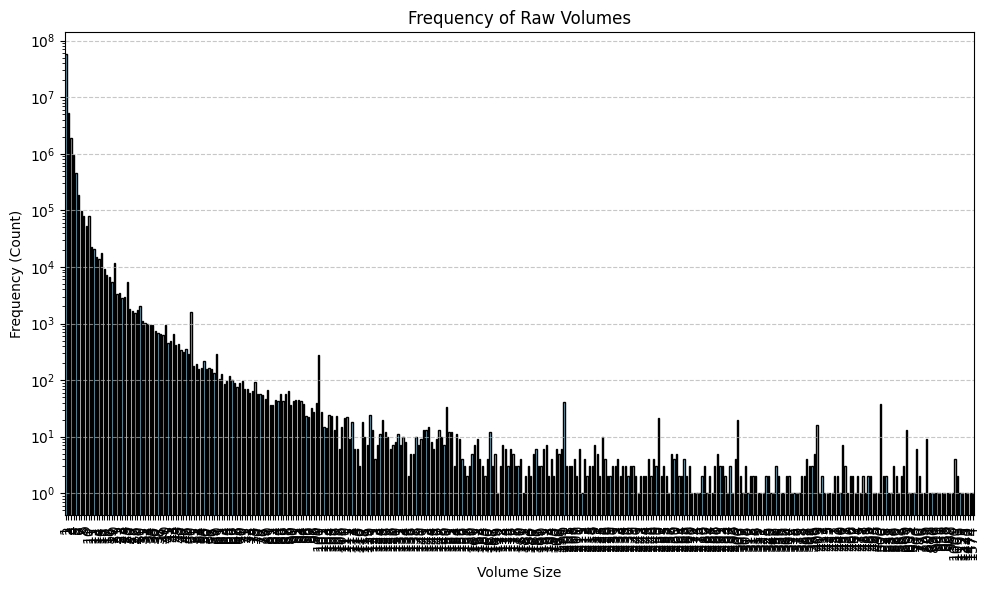

In [4]:
import matplotlib.pyplot as plt

# Calculate the frequencies and sort by volume size for a cleaner plot
volume_counts = pd.Series(td.get_raw_volumes()).value_counts().sort_index()

# Generate the bar plot
plt.figure(figsize=(10, 6))
volume_counts.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Frequency of Raw Volumes')
plt.yscale('log')
plt.xlabel('Volume Size')
plt.ylabel('Frequency (Count)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

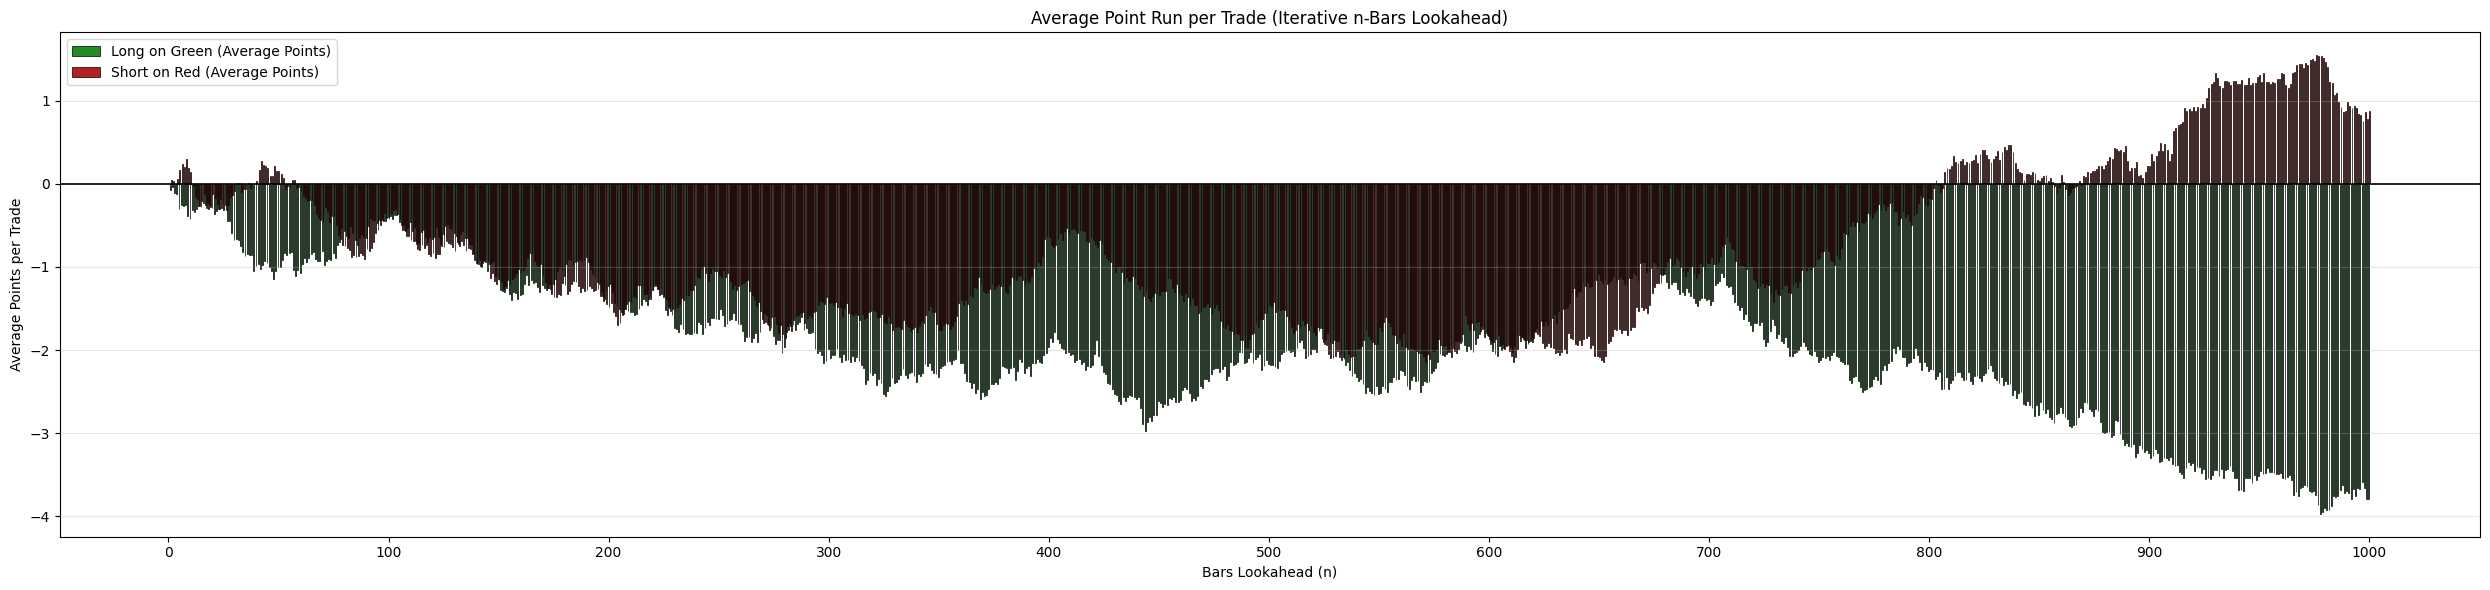

Total Long Entries Processed: 698
Total Short Entries Processed: 762

             Avg_Long_Points  Avg_Short_Points
Bars_Ahead                                   
1                 -0.074140          0.048228
2                 -0.041189          0.029528
3                 -0.108166         -0.003281
4                 -0.126791          0.052493
5                 -0.308739          0.163058
...                     ...               ...
996               -3.668338          0.831037
997               -3.587751          0.756234
998               -3.663682          0.859252
999               -3.786891          0.778215
1000              -3.791189          0.870407

[1000 rows x 2 columns]


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def evaluate_wickless_average_run(df, max_lookahead=1000):
    """
    Evaluates the average point run per trade of entering at the close of wickless candlesticks 
    using sequential index stepping.
    """
    
    # 1. Extract to numpy arrays for O(1) indexed access speed
    O = df['Open'].values
    H = df['High'].values
    L = df['Low'].values
    C = df['Close'].values
    n_bars = len(df)
    
    # Pre-allocate point sum arrays for the lookahead intervals
    bull_points_sum = np.zeros(max_lookahead)
    bear_points_sum = np.zeros(max_lookahead)
    
    bull_count = 0
    bear_count = 0
    
    # 2. Step through each bar by index
    for i in range(n_bars):
        # Long entry: Green candle with no bottom wick
        if C[i] > O[i] and np.isclose(O[i], L[i]):
            bull_count += 1
            
            # Step forward to evaluate each lookahead horizon
            for j in range(1, max_lookahead + 1):
                if i + j < n_bars:
                    # Long Points: Exit Price - Entry Price
                    bull_points_sum[j-1] += (C[i+j] - C[i])
                    
        # Short entry: Red candle with no top wick
        elif C[i] < O[i] and np.isclose(O[i], H[i]):
            bear_count += 1
            
            # Step forward to evaluate each lookahead horizon
            for j in range(1, max_lookahead + 1):
                if i + j < n_bars:
                    # Short Points: Entry Price - Exit Price
                    bear_points_sum[j-1] += (C[i] - C[i+j])

    # 3. Calculate statistical mean (points per trade)
    avg_bull_points = bull_points_sum / bull_count if bull_count > 0 else np.zeros(max_lookahead)
    avg_bear_points = bear_points_sum / bear_count if bear_count > 0 else np.zeros(max_lookahead)

    # 4. Data Visualization
    bars = np.arange(1, max_lookahead + 1)
    
    plt.figure(figsize=(25, 6))
    bar_width = 0.40
    
    plt.bar(bars - bar_width/2, avg_bull_points, width=bar_width, label='Long on Green (Average Points)', color='forestgreen', edgecolor='black', linewidth=0.5)
    plt.bar(bars + bar_width/2, avg_bear_points, width=bar_width, label='Short on Red (Average Points)', color='firebrick', edgecolor='black', linewidth=0.5)
    
    plt.axhline(0, color='black', linestyle='-', linewidth=1.2)
    plt.title("Average Point Run per Trade (Iterative n-Bars Lookahead)")
    plt.xlabel("Bars Lookahead (n)")
    plt.ylabel("Average Points per Trade")
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    
    if max_lookahead > 50:
        plt.xticks(np.arange(0, max_lookahead + 1, max_lookahead // 10))
    else:
        plt.xticks(bars)
        
    plt.tight_layout()
    plt.show()

    # 5. Return structured data
    results_df = pd.DataFrame({
        'Bars_Ahead': bars,
        'Avg_Long_Points': avg_bull_points,
        'Avg_Short_Points': avg_bear_points
    }).set_index('Bars_Ahead')
    
    print(f"Total Long Entries Processed: {bull_count}")
    print(f"Total Short Entries Processed: {bear_count}")
    
    return results_df

# --- Execution Example ---
# To run on actual E-mini S&P 500 tick data, replace the synthetic generation below with:
# df = pd.read_csv("ES_Tick_Data.csv")

# Synthetic data generation for isolated testing

test_df = pd.DataFrame({'Open': ohlc[:, 0], 'High': ohlc[:, 1], 'Low': ohlc[:, 2], 'Close': ohlc[:, 3]})

# Run the quantitative evaluation
results = evaluate_wickless_average_run(test_df)
print("\n", results)

In [6]:
import numpy as np


def adaptive_supersmoother(price, default_period=20, is_contra_trend=False, rms_len=20):

    """

    Dramatically reduced Ehlers Adaptive SuperSmoother.

    Matches the NinjaTrader C# implementation.

   

    is_contra_trend = False (Jack): Period shrinks with volatility (-)

    is_contra_trend = True  (Jill): Period grows with volatility (+)

    """

    n = len(price)

   

    # Initialize arrays. ss starts as a copy of price to handle bars < 2 inherently.

    ss = np.array(price, dtype=float)

    period = np.full(n, float(default_period))

    roc = np.zeros(n)

   

    # + for Contra-Trend (Jill), - for Trend (Jack)

    sign = 1 if is_contra_trend else -1  


    for i in range(2, n):

        # 1. Calculate SuperSmoother using previous bar's period

        p = max(period[i - 1], 2)

        Q = np.exp(-1.414 * np.pi / p)

        c1, c2 = 2 * Q * np.cos(1.414 * np.pi / p), Q * Q

       

        ss[i] = ((1 - c1 + c2) / 2) * (price[i] + price[i - 1]) + c1 * ss[i - 1] - c2 * ss[i - 2]

       

        # 2. Calculate Rate of Change (ROC)

        roc[i] = ss[i] - ss[i - 1]

       

        # 3. Calculate Rolling Root Mean Square (RMS) of the ROC

        start = max(0, i - rms_len + 1)

        roc_rms = np.sqrt(np.mean(roc[start:i + 1] ** 2))

       

        # 4. Normalize and cap rawROC at 3 (matching NinjaTrader logic)

        raw_roc = min(abs(roc[i] / roc_rms) if roc_rms != 0 else 0, 3)

       

        # 5. Set the next period using the +/- sign toggle

        period[i] = max(default_period * (1 + sign * 0.5 * raw_roc) ** 2, 2)


    return ss


no_trend = adaptive_supersmoother(close, default_period=20, is_contra_trend=True)

adaptive = adaptive_supersmoother(close, default_period=20, is_contra_trend=False) 

--- Realized PnL Statistics by ATR Regime ---
                count  mean   std    min   25%   50%  75%    max
ATR_Regime                                                      
Low (Q1)       1020.0  1.03  5.65 -12.00 -1.75 -0.38  2.0  66.75
Mid-Low (Q2)   1014.0  1.29  6.24 -10.00 -2.50 -0.50  2.5  43.75
Mid-High (Q3)  1027.0  1.59  7.55 -11.00 -2.75 -0.50  3.5  43.50
High (Q4)      1007.0  1.72  9.98 -16.75 -4.50 -1.00  4.5  79.00


C:\Users\ryany\AppData\Local\Temp\ipykernel_23868\170519890.py:56: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = trade_df.groupby('ATR_Regime')['PnL'].describe(percentiles=[0.25, 0.5, 0.75]).round(2)


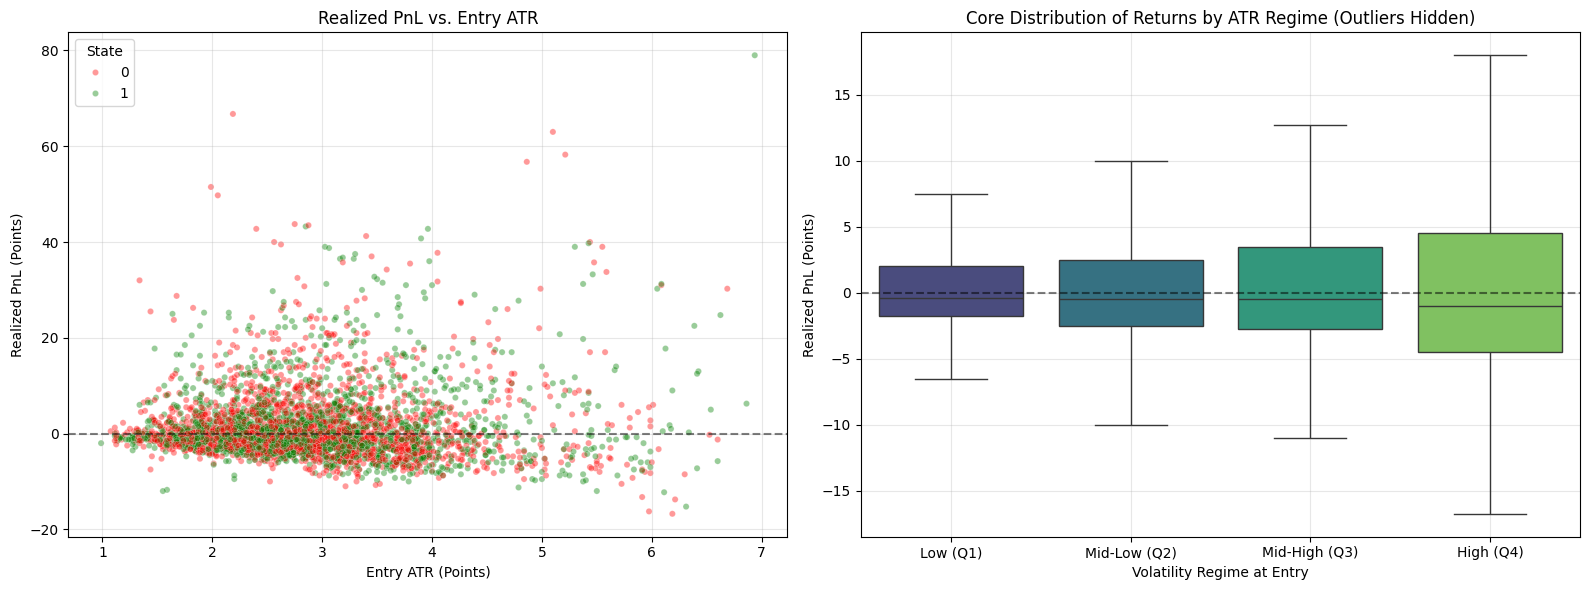

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Structure DataFrame and Calculate Volatility
df = pd.DataFrame({
    'Open': ohlc[:, 0],
    'High': ohlc[:, 1],
    'Low': ohlc[:, 2],
    'Close': ohlc[:, 3],
    'State': (adaptive > no_trend).astype(int)
})

df['prev_close'] = df['Close'].shift(1)
df['TR'] = np.maximum(df['High'] - df['Low'], 
           np.maximum(np.abs(df['High'] - df['prev_close']), 
                      np.abs(df['Low'] - df['prev_close'])))
df['ATR'] = df['TR'].rolling(20).mean()

# 2. Identify Continuous Regimes
df['Crossover'] = df['State'].diff().fillna(0) != 0
df['Regime_ID'] = df['Crossover'].cumsum()

trades = []

# 3. Calculate Realized PnL per Regime
for regime_id, group in df.groupby('Regime_ID'):
    if len(group) < 2:
        continue
        
    state = group['State'].iloc[0]
    entry_price = group['Open'].iloc[0]
    exit_price = group['Close'].iloc[-1]
    entry_atr = group['ATR'].iloc[0]
    
    if pd.isna(entry_atr) or entry_atr == 0:
        continue
        
    # Raw point PnL (no arbitrary TP/SL hit, purely mechanical regime exit)
    pnl = exit_price - entry_price if state == 1 else entry_price - exit_price
    
    trades.append({
        'State': state,
        'Entry_ATR': entry_atr,
        'PnL': pnl
    })

trade_df = pd.DataFrame(trades)

# 4. Bin ATR into 4 Volatility Regimes (Quantiles)
trade_df['ATR_Regime'] = pd.qcut(trade_df['Entry_ATR'], q=4, labels=['Low (Q1)', 'Mid-Low (Q2)', 'Mid-High (Q3)', 'High (Q4)'])

# 5. Output Statistical Summary
print("--- Realized PnL Statistics by ATR Regime ---")
summary = trade_df.groupby('ATR_Regime')['PnL'].describe(percentiles=[0.25, 0.5, 0.75]).round(2)
print(summary.to_string())

# 6. Visualize Returns vs. Volatility
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Scatter of ATR vs PnL
sns.scatterplot(data=trade_df, x='Entry_ATR', y='PnL', hue='State', palette={1: 'green', 0: 'red'}, alpha=0.4, s=20, ax=axes[0])
axes[0].axhline(0, color='black', linestyle='--', alpha=0.5)
axes[0].set_title('Realized PnL vs. Entry ATR')
axes[0].set_xlabel('Entry ATR (Points)')
axes[0].set_ylabel('Realized PnL (Points)')
axes[0].grid(True, alpha=0.3)

# Plot 2: Boxplot of PnL by ATR Quantile
# Note: showfliers=False removes extreme outliers visually to expose the core IQR structure
sns.boxplot(data=trade_df, x='ATR_Regime', y='PnL', hue='ATR_Regime', palette='viridis', showfliers=False, ax=axes[1])
axes[1].axhline(0, color='black', linestyle='--', alpha=0.5)
axes[1].set_title('Core Distribution of Returns by ATR Regime (Outliers Hidden)')
axes[1].set_xlabel('Volatility Regime at Entry')
axes[1].set_ylabel('Realized PnL (Points)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

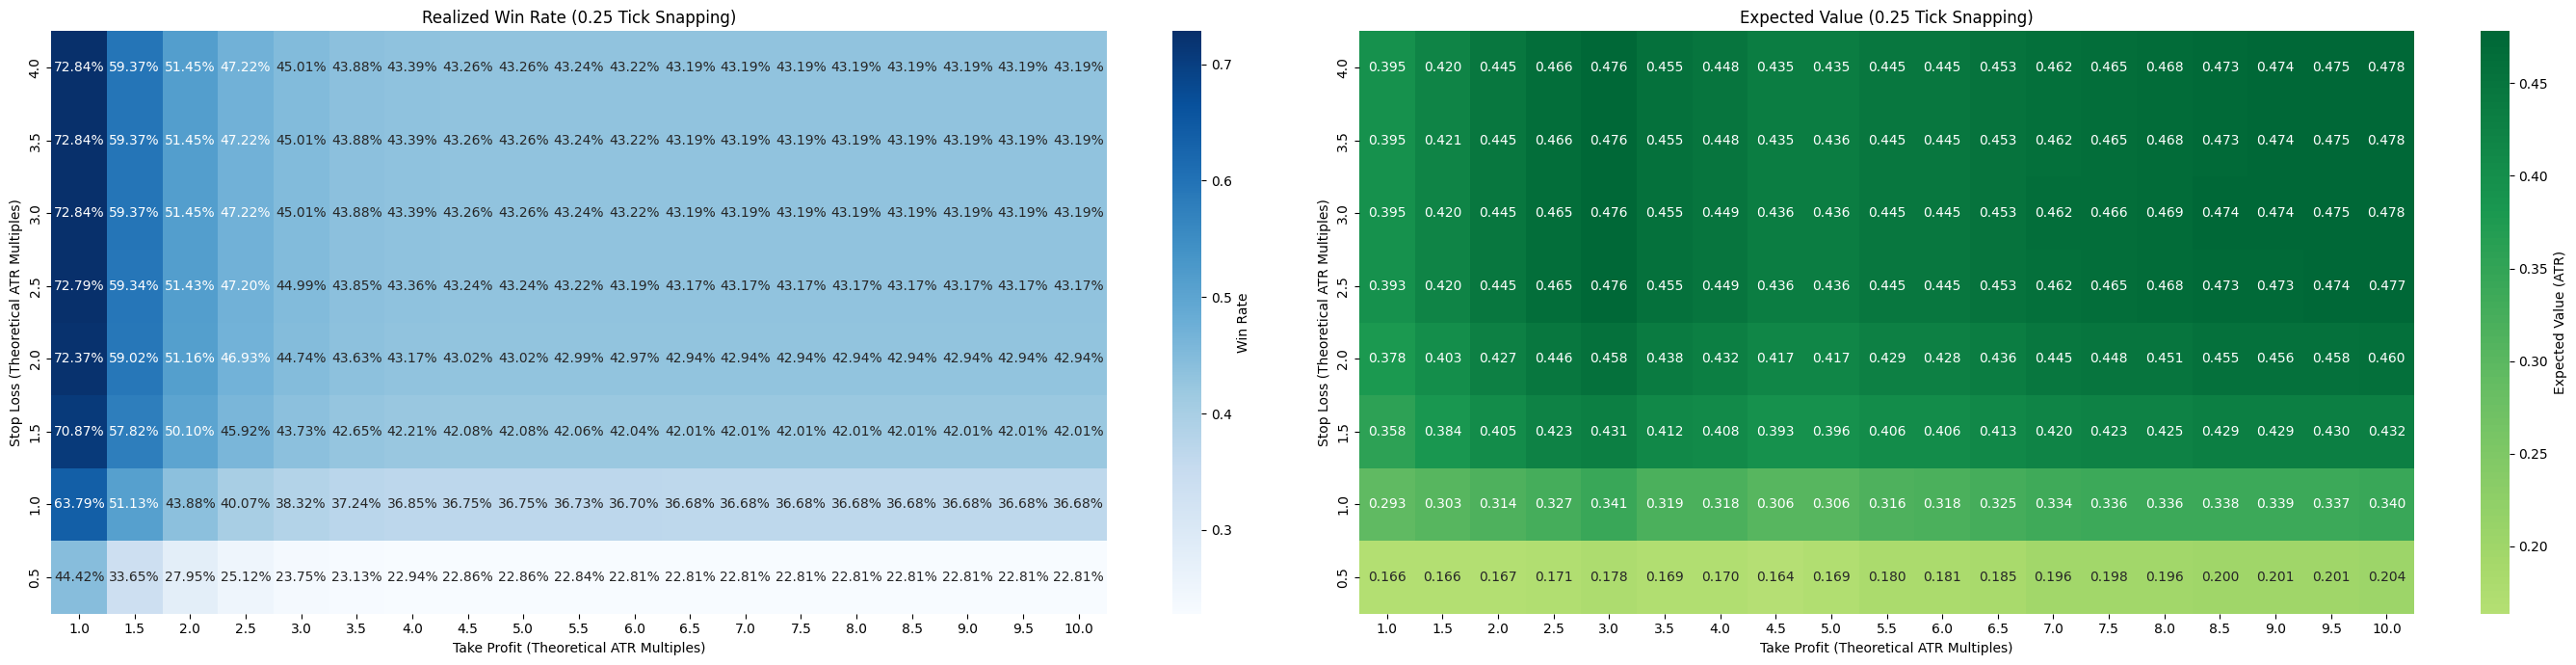

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Structure DataFrame and Calculate Volatility
df = pd.DataFrame({
    'Open': ohlc[:, 0],
    'High': ohlc[:, 1],
    'Low': ohlc[:, 2],
    'Close': ohlc[:, 3],
    'State': (adaptive > no_trend).astype(int)
})

df['prev_close'] = df['Close'].shift(1)
df['TR'] = np.maximum(df['High'] - df['Low'], 
           np.maximum(np.abs(df['High'] - df['prev_close']), 
                      np.abs(df['Low'] - df['prev_close'])))
df['ATR'] = df['TR'].rolling(20).mean()

df['Crossover'] = df['State'].diff().fillna(0) != 0
df['Regime_ID'] = df['Crossover'].cumsum()

# 2. High-Win-Rate Grid Parameters
tp_mults = np.arange(1.0, 10.5, 0.5)
sl_mults = np.arange(0.5, 4.5, 0.5)
tick_size = 0.25  # Force ES tick increments

grid = {(tp, sl): {'total_pnl_atr': 0.0, 'wins': 0, 'trades': 0} for tp in tp_mults for sl in sl_mults}

# 3. Bar-by-Bar Barrier Evaluation with Tick Rounding
for regime_id, group in df.groupby('Regime_ID'):
    if len(group) < 2:
        continue
        
    state = group['State'].iloc[0]
    entry_price = group['Open'].iloc[0]
    entry_atr = group['ATR'].iloc[0]
    
    if pd.isna(entry_atr) or entry_atr == 0:
        continue
        
    highs = group['High'].values
    lows = group['Low'].values
    closes = group['Close'].values
    length = len(highs)
    
    for tp in tp_mults:
        for sl in sl_mults:
            if state == 1:
                # Snap long targets to nearest 0.25 tick
                tp_price = np.round((entry_price + tp * entry_atr) / tick_size) * tick_size
                sl_price = np.round((entry_price - sl * entry_atr) / tick_size) * tick_size
                
                tp_hits = highs >= tp_price
                sl_hits = lows <= sl_price
            else:
                # Snap short targets to nearest 0.25 tick
                tp_price = np.round((entry_price - tp * entry_atr) / tick_size) * tick_size
                sl_price = np.round((entry_price + sl * entry_atr) / tick_size) * tick_size
                
                tp_hits = lows <= tp_price
                sl_hits = highs >= sl_price
            
            tp_idx = np.argmax(tp_hits) if np.any(tp_hits) else length
            sl_idx = np.argmax(sl_hits) if np.any(sl_hits) else length
            
            # 4. Calculate Exact Realized Point PnL
            if tp_idx == length and sl_idx == length:
                raw_pnl = closes[-1] - entry_price if state == 1 else entry_price - closes[-1]
            elif tp_idx < sl_idx:
                raw_pnl = tp_price - entry_price if state == 1 else entry_price - tp_price
            elif sl_idx < tp_idx:
                raw_pnl = sl_price - entry_price if state == 1 else entry_price - sl_price
            else:
                # Pessimistic tie penalty evaluates to stop loss price
                raw_pnl = sl_price - entry_price if state == 1 else entry_price - sl_price 
                
            # Convert tick-rounded PnL back to ATR units for standardized EV computation
            realized_atr = raw_pnl / entry_atr
            
            grid[(tp, sl)]['total_pnl_atr'] += realized_atr
            grid[(tp, sl)]['trades'] += 1
            if raw_pnl > 0:
                grid[(tp, sl)]['wins'] += 1

# 5. Calculate Expected Value and Formatting
results = []
for (tp, sl), metrics in grid.items():
    trades = metrics['trades']
    if trades > 0:
        win_rate = metrics['wins'] / trades
        ev = metrics['total_pnl_atr'] / trades 
    else:
        win_rate, ev = 0, 0
    results.append({'TP_ATR': tp, 'SL_ATR': sl, 'WinRate': win_rate, 'EV_ATR': ev})

res_df = pd.DataFrame(results)

wr_pivot = res_df.pivot(index='SL_ATR', columns='TP_ATR', values='WinRate')
ev_pivot = res_df.pivot(index='SL_ATR', columns='TP_ATR', values='EV_ATR')

# 6. Visualize Grid Search Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(28, 7))

sns.heatmap(wr_pivot, annot=True, fmt=".2%", cmap="Blues", cbar_kws={'label': 'Win Rate'}, ax=axes[0])
axes[0].set_title('Realized Win Rate (0.25 Tick Snapping)')
axes[0].set_ylabel('Stop Loss (Theoretical ATR Multiples)')
axes[0].set_xlabel('Take Profit (Theoretical ATR Multiples)')
axes[0].invert_yaxis()

sns.heatmap(ev_pivot, annot=True, fmt=".3f", cmap="RdYlGn", center=0, cbar_kws={'label': 'Expected Value (ATR)'}, ax=axes[1])
axes[1].set_title('Expected Value (0.25 Tick Snapping)')
axes[1].set_ylabel('Stop Loss (Theoretical ATR Multiples)')
axes[1].set_xlabel('Take Profit (Theoretical ATR Multiples)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

In [24]:
import numpy as np
import pandas as pd

# Extracts OHLC arrays and computes the global mean of the 20-period ATR
df_temp = pd.DataFrame({
    'High': ohlc[:, 1],
    'Low': ohlc[:, 2],
    'Close': ohlc[:, 3]
})

df_temp['prev_close'] = df_temp['Close'].shift(1)
df_temp['TR'] = np.maximum(df_temp['High'] - df_temp['Low'], 
                np.maximum(np.abs(df_temp['High'] - df_temp['prev_close']), 
                           np.abs(df_temp['Low'] - df_temp['prev_close'])))

# Calculate 20-period ATR, then find the overall average
global_avg_atr = df_temp['TR'].rolling(20).mean().describe()

print(global_avg_atr)

count    66420.000000
mean         2.921016
std          0.982543
min          0.950000
25%          2.262500
50%          2.750000
75%          3.375000
max         11.962500
Name: TR, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
from Engine.Report import generate_report

# 1. Precompute Volatility and State
df_temp = pd.DataFrame({
    'Open': ohlc[:, 0],
    'High': ohlc[:, 1],
    'Low': ohlc[:, 2],
    'Close': ohlc[:, 3]
})

df_temp['prev_close'] = df_temp['Close'].shift(1)
df_temp['TR'] = np.maximum(df_temp['High'] - df_temp['Low'], 
                np.maximum(np.abs(df_temp['High'] - df_temp['prev_close']), 
                           np.abs(df_temp['Low'] - df_temp['prev_close'])))

atr = df_temp['TR'].rolling(20).mean().values
state = (adaptive > no_trend).astype(int)
highs = df_temp['High'].values
lows = df_temp['Low'].values
opens = df_temp['Open'].values

# 2. Initialize Signal Array and Barrier Multipliers
signal = np.zeros(len(ohlc))
current_pos = 0  
tp_price = 0.0
sl_price = 0.0
tick_size = 0.25

# Optimal Grid Search Parameters
tp_mult = 3.0  
sl_mult = 3.0

# 3. Bar-by-Bar Signal Generation
for i in range(20, len(ohlc)):
    prev_state = state[i-1]
    current_state = state[i] 
    
    # Check TP and SL breaches during the current bar
    if current_pos == 1:
        if highs[i] >= tp_price or lows[i] <= sl_price:
            current_pos = 0
    elif current_pos == -1:
        if lows[i] <= tp_price or highs[i] >= sl_price:
            current_pos = 0
            
    # Monitor for structural regime reversals (Unshifted)
    if current_state != prev_state:
        entry_price = opens[i]
        entry_atr = atr[i]
        
        # Only enter if volatility is valid
        if not pd.isna(entry_atr) and entry_atr > 0:
            if current_state == 1:
                current_pos = 1
                tp_price = np.round((entry_price + tp_mult * entry_atr) / tick_size) * tick_size
                sl_price = np.round((entry_price - sl_mult * entry_atr) / tick_size) * tick_size
            else:
                current_pos = -1
                tp_price = np.round((entry_price - tp_mult * entry_atr) / tick_size) * tick_size
                sl_price = np.round((entry_price + sl_mult * entry_atr) / tick_size) * tick_size

    signal[i] = current_pos

# 4. Execute Custom Backtester
bt = Backtester(
    ohlc=ohlc,
    indicies=indices,
    signal=signal,
    timeframe=timeframe,
    tick_value=tick_value,
    contract_multiplier=contract_multiplier,
    initial_equity=initial_equity,
    slippage_ticks=0,
    commission=0,
)
bt.full_backtest()
print(f"Final Equity: {bt.final_equity}")
print(bt)

generate_report(bt, 'backtest_report.html', open_browser=True)

Final Equity: 83875.0

        Backtest Results from 2026-01-01 23:02:37.009120-06:00 to 2026-03-02 07:29:21.001600-06:00 (59 days 08:26:43.992480)
        Equity:     $100,000.00 -> $83,875.00
        Buy & Hold: $100,000.00 -> $94,850.00
        Buy & Hold Return (%): -5.15%
        Strategy Return (%):   -16.12%

        Total Trades:     4279.00
        Win Rate:         53.17%
        95% CI:           51.67% - 54.66%
        Avg. Win:         $147.69
        Avg. Loss:        $-182.45
        Ratio Win/Loss:   0.81
        Expected Value:   $-6.92

        Largest Win:      $1,375.00
        Largest Loss:     $-2,887.50
        Max Consec. Wins: 13
        Max Consec. Loss: 12

        Max Drawdown from 2026-02-04 00:00:06.009440-06:00 to 2026-02-26 16:22:12.005520-06:00 (22 days 16:22:05.996080)
        Max Drawdown:     $-23,700.00
        Max Drawdown (%): -22.90%

        Slippage:   0 ticks
        Commission: $0.00
        Contract Multiplier: $50.00
        Transaction Cos

'C:\\Users\\ryany\\OneDrive\\Desktop\\Futures-PC\\MacLink\\RugbeatunoBacktestingSuite\\backtest_report.html'

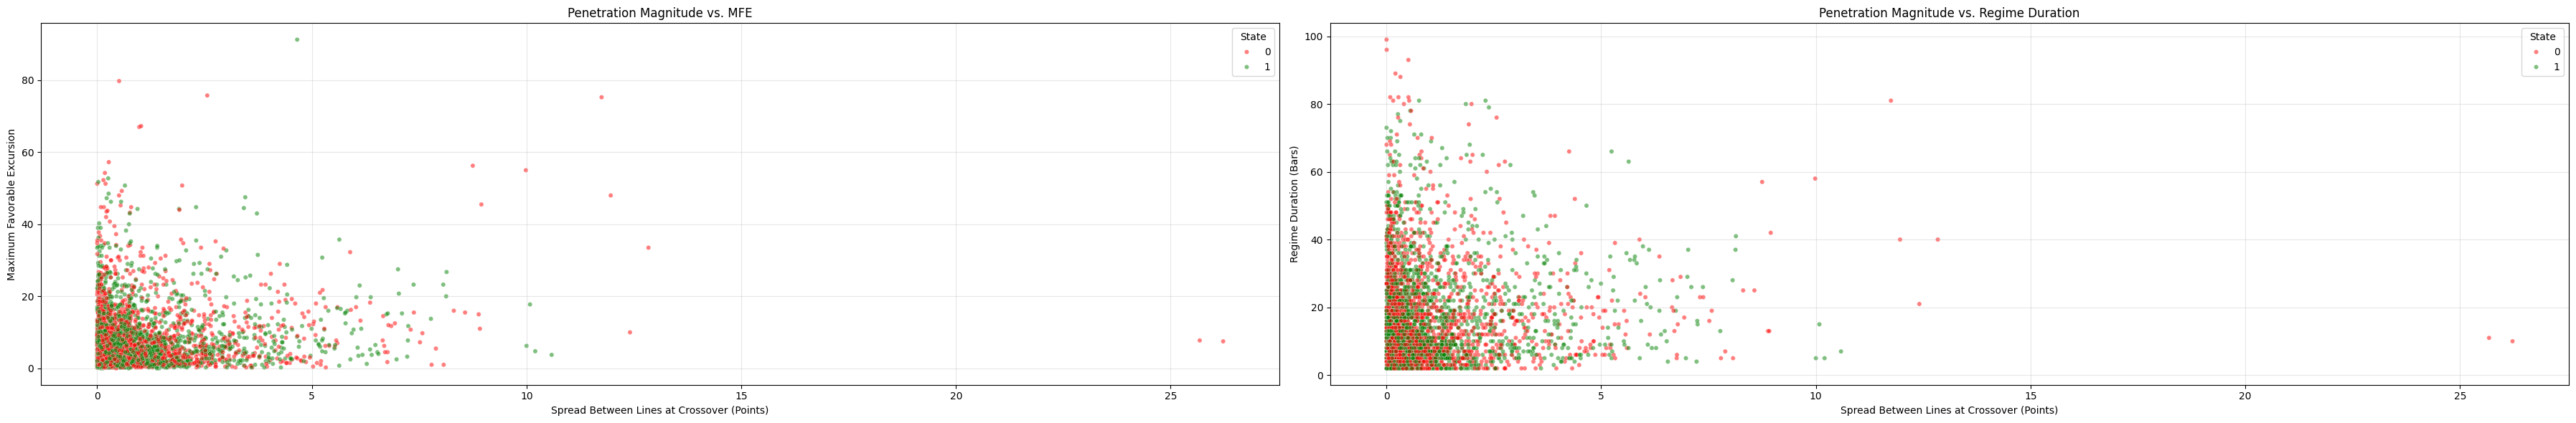

--- Correlation: Penetration Magnitude vs Outcomes ---
             Penetration    MFE    MAE  Duration
Penetration        1.000  0.150  0.219     0.078
MFE                0.150  1.000 -0.303     0.829
MAE                0.219 -0.303  1.000    -0.340
Duration           0.078  0.829 -0.340     1.000


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Structure the DataFrame, now including the indicator arrays
df = pd.DataFrame({
    'Open': ohlc[:, 0],
    'High': ohlc[:, 1],
    'Low': ohlc[:, 2],
    'Adaptive': adaptive,
    'NoTrend': no_trend,
    'State': (adaptive > no_trend).astype(int)
})

# 2. Identify regimes
df['Crossover'] = df['State'].diff().fillna(0) != 0
df['Regime_ID'] = df['Crossover'].cumsum()

excursions = []

# 3. Compute metrics for each regime
for regime_id, group in df.groupby('Regime_ID'):
    if len(group) < 2:
        continue
        
    state = group['State'].iloc[0]
    entry_price = group['Open'].iloc[0]
    
    # Calculate Penetration Magnitude at the exact moment of crossover
    adaptive_val = group['Adaptive'].iloc[0]
    notrend_val = group['NoTrend'].iloc[0]
    penetration = abs(adaptive_val - notrend_val)
    
    max_high = group['High'].max()
    min_low = group['Low'].min()
    
    if state == 1:
        mfe = max_high - entry_price
        mae = entry_price - min_low
    else:
        mfe = entry_price - min_low
        mae = max_high - entry_price
        
    excursions.append({
        'State': state,
        'Penetration': penetration,
        'MFE': mfe,
        'MAE': mae,
        'Duration': len(group)
    })

ex_df = pd.DataFrame(excursions)

# 4. Visualize the predictive power of Penetration Magnitude
fig, axes = plt.subplots(1, 2, figsize=(36, 6))

# Plot 1: Penetration vs. MFE
sns.scatterplot(data=ex_df, x='Penetration', y='MFE', hue='State', 
                palette={1: 'green', 0: 'red'}, alpha=0.5, s=20, ax=axes[0])
axes[0].set_title('Penetration Magnitude vs. MFE')
axes[0].set_xlabel('Spread Between Lines at Crossover (Points)')
axes[0].set_ylabel('Maximum Favorable Excursion')
axes[0].grid(True, alpha=0.3)

# Plot 2: Penetration vs. Regime Duration
sns.scatterplot(data=ex_df, x='Penetration', y='Duration', hue='State', 
                palette={1: 'green', 0: 'red'}, alpha=0.5, s=20, ax=axes[1])
axes[1].set_title('Penetration Magnitude vs. Regime Duration')
axes[1].set_xlabel('Spread Between Lines at Crossover (Points)')
axes[1].set_ylabel('Regime Duration (Bars)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5. Output Correlation Metrics
print("--- Correlation: Penetration Magnitude vs Outcomes ---")
print(ex_df[['Penetration', 'MFE', 'MAE', 'Duration']].corr().round(3).to_string())

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider

def calculate_crossover_probabilities(distance, slope, duration, max_n=20):
    # state_sign: +1 implies adaptive is above, -1 implies below
    state_sign = np.sign(duration) if duration != 0 else 1
    abs_duration = abs(duration)
    
    # Counter-trend momentum:
    # If currently above (+), a negative slope opposes the state.
    # If currently below (-), a positive slope opposes the state.
    counter_trend_momentum = -state_sign * slope
    
    pdf = np.zeros(max_n)
    cdf = np.zeros(max_n)
    survival_prob = 1.0
    
    for t in range(1, max_n + 1):
        # Hazard function z-score (replace with your trained empirical weights)
        # 1. distance suppresses crossover risk (-1.5)
        # 2. counter-trend momentum accelerates risk (+1.2)
        # 3. duration adds minor mean-reversion decay (+0.02)
        # 4. t adds baseline temporal decay (+0.05)
        z = -2.0 - (1.5 * distance) + (1.2 * counter_trend_momentum) + (0.02 * abs_duration) + (0.05 * t)
        
        # Hazard rate h(t): Probability of crossing exactly at t, given survival to t-1
        hazard_rate = 1 / (1 + np.exp(-z))
        
        # PDF: Probability of crossing EXACTLY at timport numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider

def calculate_crossover_probabilities(distance, slope, duration, max_n=20):
    # state_sign: +1 implies adaptive is above, -1 implies below
    state_sign = np.sign(duration) if duration != 0 else 1
    abs_duration = abs(duration)
    
    # Counter-trend momentum:
    # If currently above (+), a negative slope opposes the state.
    # If currently below (-), a positive slope opposes the state.
    counter_trend_momentum = -state_sign * slope
    
    pdf = np.zeros(max_n)
    cdf = np.zeros(max_n)
    survival_prob = 1.0
    
    for t in range(1, max_n + 1):
        # Hazard function z-score (replace with your trained empirical weights)
        # 1. distance suppresses crossover risk (-1.5)
        # 2. counter-trend momentum accelerates risk (+1.2)
        # 3. duration adds minor mean-reversion decay (+0.02)
        # 4. t adds baseline temporal decay (+0.05)
        z = -2.0 - (1.5 * distance) + (1.2 * counter_trend_momentum) + (0.02 * abs_duration) + (0.05 * t)
        
        # Hazard rate h(t): Probability of crossing exactly at t, given survival to t-1
        hazard_rate = 1 / (1 + np.exp(-z))
        
        # PDF: Probability of crossing EXACTLY at t
        prob_at_t = hazard_rate * survival_prob
        pdf[t-1] = prob_at_t
        
        # CDF: Cumulative sum of PDF
        if t == 1:
            cdf[t-1] = prob_at_t
        else:
            cdf[t-1] = cdf[t-2] + prob_at_t
            
        # Update survival probability for t+1
        survival_prob *= (1 - hazard_rate)
        
    return pdf, cdf

def plot_probabilities(norm_distance=1.0, norm_slope=-0.5, duration=10):
    max_n = 20
    pdf, cdf = calculate_crossover_probabilities(norm_distance, norm_slope, duration, max_n)
    
    n_range = np.arange(1, max_n + 1)
    
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(n_range, pdf, alpha=0.6, label='PDF (Exact Candle Cross)', color='blue')
    ax.plot(n_range, cdf, marker='o', label='CDF (Cumulative Probability)', color='red', linewidth=2)
    
    ax.set_title(f"Predicted Regime Crossover Probability\nDist: {norm_distance} | Slope: {norm_slope} | Dur: {duration}")
    ax.set_xlabel("Bars in the Future (n)")
    ax.set_ylabel("Probability")
    ax.set_ylim(0, 1.05)
    ax.set_xticks(n_range)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.legend(loc="upper left")
    
    plt.show()

# Render the interactive UI in the cell output
interact(plot_probabilities, 
         norm_distance=FloatSlider(value=1.0, min=0.0, max=5.0, step=0.1, description='Norm Dist'),
         norm_slope=FloatSlider(value=-0.5, min=-3.0, max=3.0, step=0.1, description='Norm Slope'),
         duration=IntSlider(value=10, min=-50, max=50, step=1, description='Duration'));
        prob_at_t = hazard_rate * survival_prob
        pdf[t-1] = prob_at_t
        
        # CDF: Cumulative sum of PDF
        if t == 1:
            cdf[t-1] = prob_at_t
        else:
            cdf[t-1] = cdf[t-2] + prob_at_t
            
        # Update survival probability for t+1
        survival_prob *= (1 - hazard_rate)
        
    return pdf, cdf

def plot_probabilities(norm_distance=1.0, norm_slope=-0.5, duration=10):
    max_n = 20
    pdf, cdf = calculate_crossover_probabilities(norm_distance, norm_slope, duration, max_n)
    
    n_range = np.arange(1, max_n + 1)
    
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(n_range, pdf, alpha=0.6, label='PDF (Exact Candle Cross)', color='blue')
    ax.plot(n_range, cdf, marker='o', label='CDF (Cumulative Probability)', color='red', linewidth=2)
    
    ax.set_title(f"Predicted Regime Crossover Probability\nDist: {norm_distance} | Slope: {norm_slope} | Dur: {duration}")
    ax.set_xlabel("Bars in the Future (n)")
    ax.set_ylabel("Probability")
    ax.set_ylim(0, 1.05)
    ax.set_xticks(n_range)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.legend(loc="upper left")
    
    plt.show()

# Render the interactive UI in the cell output
interact(plot_probabilities, 
         norm_distance=FloatSlider(value=1.0, min=0.0, max=5.0, step=0.1, description='Norm Dist'),
         norm_slope=FloatSlider(value=-0.5, min=-3.0, max=3.0, step=0.1, description='Norm Slope'),
         duration=IntSlider(value=10, min=-50, max=50, step=1, description='Duration'));

KeyError: 'Open'

In [11]:
import numpy as np
import pandas as pd


def calc_ehlers_fm_super(close_prices, sig_period=6):
    """
    Calculates the Ehlers FM Demodulator integrated with a SuperSmoother.
    
    Parameters:
    close_prices (pd.Series or np.array): Time series of close prices.
    sig_period (int): Length of the SuperSmoother (default is 6).
    
    Returns:
    pd.Series: The smoothed FM Oscillator values.
    """
    close = pd.Series(close_prices)
    
    # 1. Derivative of the price wave (Close[0] - Close[2])
    deriv = close - close.shift(2)
    
    # 2. Normalize Degap to half RMS (over 50 bars)
    # Calculate the sum of squares over a 50-bar rolling window, then divide by 50 and sqrt
    deriv_sq = deriv ** 2
    rms = np.sqrt(deriv_sq.rolling(window=50).mean())
    
    # Prevent division by zero
    rms = rms.replace(0, np.nan)
    
    # Calculate clip and hard limit at +/- 1
    clip = (2 * deriv) / rms
    clip = clip.clip(lower=-1, upper=1)
    
    # 3. Z3 to integrate derivative (sum of current and 3 previous clips)
    z3 = clip.rolling(window=4).sum()
    
    # 4. Calculate SuperSmoother coefficients
    f = (1.414 * np.pi) / sig_period
    a1 = np.exp(-f)
    c2 = 2 * a1 * np.cos(f)
    c3 = -a1 * a1
    c1 = 1 - c2 - c3
    
    # 5. Apply the SuperSmoother to the Z3 Integrated Signal (Recursive)
    super_series = np.zeros(len(close))
    z3_arr = z3.to_numpy()
    print(z3_arr)
    
    for i in range(len(close)):
        # Wait until sufficient data has populated (equivalent to CurrentBar < 54)
        if i < 54:
            super_series[i] = 0
        else:
            super_series[i] = (c1 * (z3_arr[i] + z3_arr[i-1]) / 2 
                               + c2 * super_series[i-1] 
                               + c3 * super_series[i-2])
            
    return pd.Series(super_series, index=close.index, name="FM_SuperSmoother")

# --- Example Usage in Jupyter ---
# import yfinance as yf
# df = yf.download("ES=F", period="1mo", interval="1h")
# df['FM_Oscillator'] = calc_ehlers_fm_super(df['Close'], sig_period=6)
# df['FM_Oscillator'].plot(title="Ehlers FM Oscillator (SuperSmoothed)", figsize=(10,4))

[        nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
  4.          4.          4.          4.          4.          4.
  4.          3.7732495   3.19689669  2.26403686  0.97361115 -0.44282761
 -1.85186598 -2.91900614 -3.62858044 -3.98539118 -4.         -4.
 -4.         -4.         -4.         -4.         -4.         -4.
 -4.         -4.         -4.         -4.         -4.         -4.
 -4.      

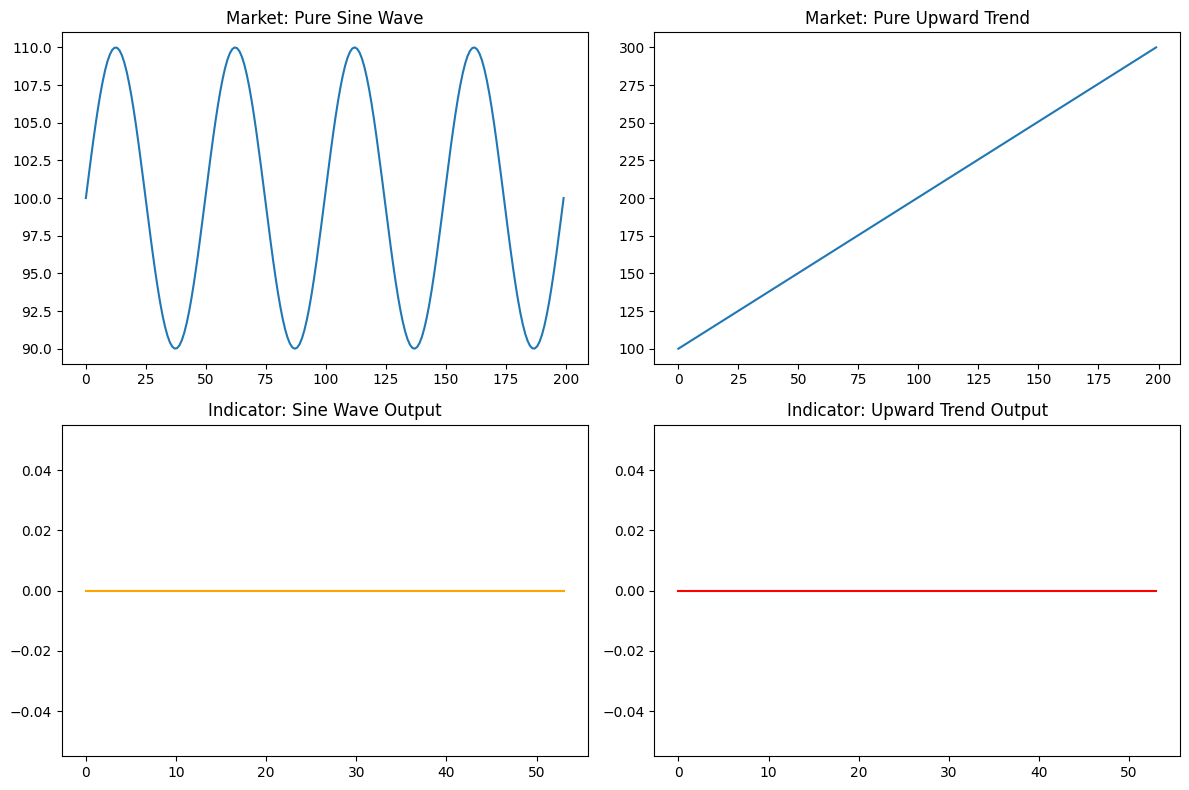

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# [Insert your calc_ehlers_fm_super function here]

# 1. Simulate Strict Sine Wave
# 200 data points, oscillating smoothly
t = np.linspace(0, 8 * np.pi, 200)
sine_prices = np.sin(t) * 10 + 100 

# 2. Simulate Strict Upward Trend
# Constant slope of +1 per bar
linear_prices = np.linspace(100, 300, 200)

# Calculate indicators
sine_fm = calc_ehlers_fm_super(sine_prices, sig_period=6)
linear_fm = calc_ehlers_fm_super(linear_prices, sig_period=6)

# Plotting the proof
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Sine Wave Plots
axes[0, 0].plot(sine_prices, label='Sine Wave Prices')
axes[0, 0].set_title('Market: Pure Sine Wave')
axes[1, 0].plot(sine_fm, color='orange', label='FM Oscillator')
axes[1, 0].set_title('Indicator: Sine Wave Output')

# Linear Trend Plots
axes[0, 1].plot(linear_prices, label='Linear Upward Trend')
axes[0, 1].set_title('Market: Pure Upward Trend')
axes[1, 1].plot(linear_fm, color='red', label='FM Oscillator')
axes[1, 1].set_title('Indicator: Upward Trend Output')

plt.tight_layout()
plt.show()

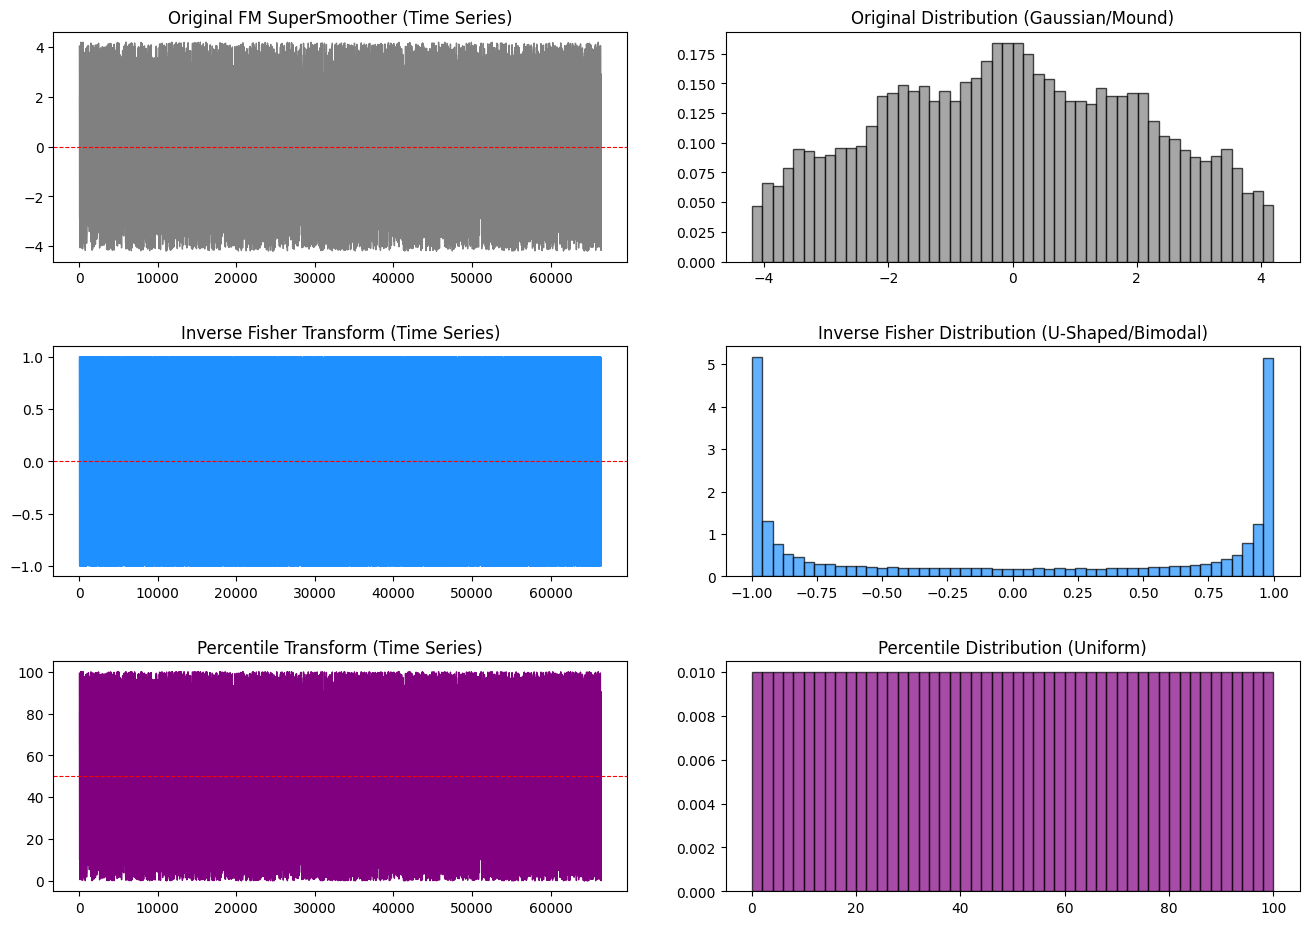

--- Distribution Kurtosis ---
Original Kurtosis: -0.8906 (Near 0 = Gaussian/Mound)
Inverse Fisher Kurtosis: -1.7399 (Negative = U-Shaped)
Percentile Kurtosis: -1.2000 (Constant = Uniform)


In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Assuming 'clean_oscillator' is already calculated from the previous cell
original = clean_oscillator

# 1. Apply Inverse Fisher Transform
# Formula: (e^(2x) - 1) / (e^(2x) + 1), equivalent to np.tanh(x)
ift_oscillator = np.tanh(original)

# 2. Apply Percentile Transform
# Converts values to their empirical cumulative distribution rank (0 to 100)
percentile_oscillator = original.rank(pct=True) * 100

# 3. Visualization Setup
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
fig.tight_layout(pad=4.0)

# Plot Original
axes[0, 0].plot(original, color='gray', linewidth=1)
axes[0, 0].set_title("Original FM SuperSmoother (Time Series)")
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=0.8)

axes[0, 1].hist(original, bins=50, color='gray', edgecolor='black', alpha=0.7, density=True)
axes[0, 1].set_title("Original Distribution (Gaussian/Mound)")

# Plot Inverse Fisher Transform
axes[1, 0].plot(ift_oscillator, color='dodgerblue', linewidth=1)
axes[1, 0].set_title("Inverse Fisher Transform (Time Series)")
axes[1, 0].axhline(0, color='red', linestyle='--', linewidth=0.8)

axes[1, 1].hist(ift_oscillator, bins=50, color='dodgerblue', edgecolor='black', alpha=0.7, density=True)
axes[1, 1].set_title("Inverse Fisher Distribution (U-Shaped/Bimodal)")

# Plot Percentile Transform
axes[2, 0].plot(percentile_oscillator, color='purple', linewidth=1)
axes[2, 0].set_title("Percentile Transform (Time Series)")
axes[2, 0].axhline(50, color='red', linestyle='--', linewidth=0.8)

axes[2, 1].hist(percentile_oscillator, bins=50, color='purple', edgecolor='black', alpha=0.7, density=True)
axes[2, 1].set_title("Percentile Distribution (Uniform)")

plt.show()

# Statistical Proof Output
print("--- Distribution Kurtosis ---")
print(f"Original Kurtosis: {original.kurtosis():.4f} (Near 0 = Gaussian/Mound)")
print(f"Inverse Fisher Kurtosis: {ift_oscillator.kurtosis():.4f} (Negative = U-Shaped)")
print(f"Percentile Kurtosis: {percentile_oscillator.kurtosis():.4f} (Constant = Uniform)")

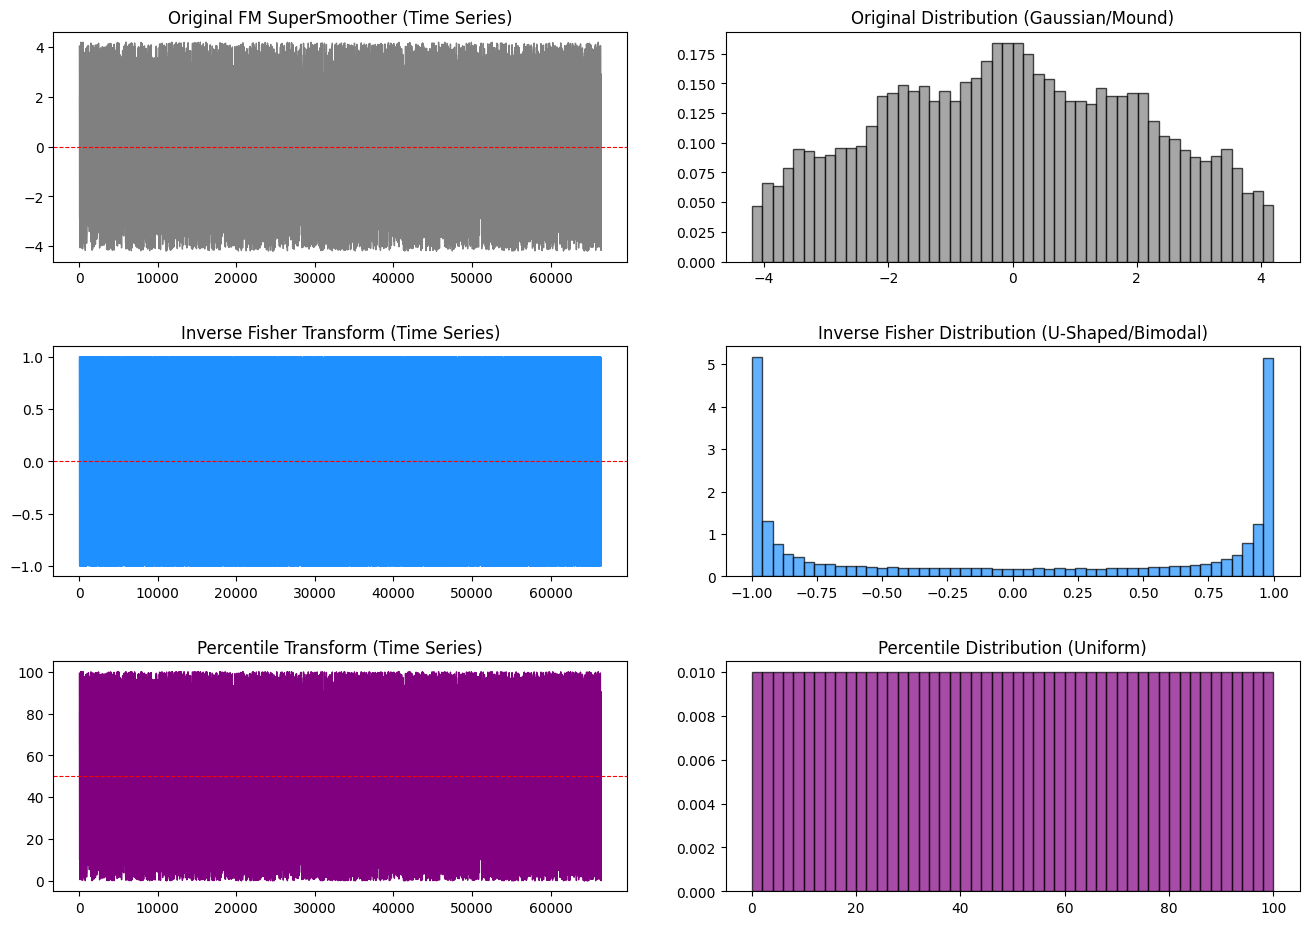

--- Distribution Kurtosis ---
Original Kurtosis: -0.8906 (Near 0 = Gaussian/Mound)
Inverse Fisher Kurtosis: -1.7399 (Negative = U-Shaped)
Percentile Kurtosis: -1.2000 (Constant = Uniform)


In [ ]:
slopes = (no_trend - adaptive)
print(f"Minimum:            {np.min(slopes)}")
print(f"Maximum:            {np.max(slopes)}")
print(f"Mean (Average):     {np.mean(slopes)}")
print(f"Median:             {np.median(slopes)}")
print(f"Variance:           {np.var(slopes)}")
print(f"Standard Deviation: {np.std(slopes)}")
print(f"25th Percentile:    {np.percentile(slopes, 1)}")
print(f"75th Percentile:    {np.percentile(slopes, 99)}")

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import ipywidgets as widgets
from IPython.display import display
import warnings
# To make the distributions easier to work with, we can optionally standardize the slopes (Z-score)
# slopes = (slopes - np.mean(slopes)) / np.std(slopes)
try:
    from hmmlearn import hmm
    HAS_HMMLEARN = True
except ImportError:
    HAS_HMMLEARN = False
    print("Note: 'hmmlearn' is not installed. The interactive plot will still work, ")
    print("but automatic HMM fitting will be skipped. Run 'pip install hmmlearn' to enable.")

if HAS_HMMLEARN:
    # Reshape data for hmmlearn (requires 2D array: samples x features)
    X = slopes.reshape(-1, 1)
    
    # Initialize a 3-state Gaussian HMM (Short, Neutral, Long)
    model = hmm.GaussianHMM(n_components=2, covariance_type="diag", n_iter=1000, random_state=42)
    model.fit(X)
    
    # Sort states by their means so State 0 = Short, 1 = Neutral, 2 = Long
    order = np.argsort(model.means_.flatten())
    fitted_means = model.means_[order].flatten()
    fitted_stds = np.sqrt(model.covars_[order].flatten())
    
    print("--- Automatically Fitted HMM States ---")
    print(f"Short State   -> Mean: {fitted_means[0]:.4f}, Std: {fitted_stds[0]:.4f}")
    print(f"Long State    -> Mean: {fitted_means[1]:.4f}, Std: {fitted_stds[1]:.4f}")
    print("-" * 39)
else:
    # Fallback default values if hmmlearn isn't installed
    fitted_means = [-0.5, 0.0, 0.5]
    fitted_stds = [0.2, 0.1, 0.2]

def plot_distributions(short_mean, short_std, long_mean, long_std):
    """
    Plots the histogram of actual indicator slopes and overlays the 3 manual Gaussian distributions.
    """
    plt.figure(figsize=(12, 6))
    
    # 1. Plot the actual histogram of the slopes
    # We drop the first few elements which might be volatile due to indicator warmup
    valid_slopes = slopes[20:] 
    plt.hist(valid_slopes, bins=80, density=True, alpha=0.4, color='gray', edgecolor='black', label='Actual Slope Histogram')
    
    # 2. Generate X values for the smooth bell curves
    x_min, x_max = np.min(valid_slopes), np.max(valid_slopes)
    x = np.linspace(x_min, x_max, 1000)
    
    # 3. Calculate and plot the Probability Density Functions (PDFs)
    short_pdf = norm.pdf(x, short_mean, short_std)
    # neutral_pdf = norm.pdf(x, neutral_mean, neutral_std)
    long_pdf = norm.pdf(x, long_mean, long_std)
    
    plt.plot(x, short_pdf, color='red', lw=3, label='Short Emission (State 0)')
    plt.fill_between(x, short_pdf, alpha=0.1, color='red')
    
    plt.plot(x, long_pdf, color='blue', lw=3, label='Neutral Emission (State 1)')
    plt.fill_between(x, long_pdf, alpha=0.1, color='blue')
    
    # plt.plot(x, long_pdf, color='green', lw=3, label='Long Emission (State 2)')
    # plt.fill_between(x, long_pdf, alpha=0.1, color='green')
    
    # 4. Formatting the chart
    plt.title('HMM Emission Distributions vs. Actual Indicator Slopes', fontsize=14)
    plt.xlabel('Indicator Slope (Bar-to-Bar Change)', fontsize=12)
    plt.ylabel('Density', fontsize=12)
    plt.axvline(0, color='black', linestyle='--', alpha=0.5)
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

# We dynamically set slider ranges based on the actual data
data_std = np.std(slopes)
data_min = np.min(slopes)
data_max = np.max(slopes)

# Create interactive sliders
interact_plot = widgets.interact(
    plot_distributions,
    short_mean=widgets.FloatSlider(value=fitted_means[0], min=data_min, max=0, step=0.01, description='Short Mean:'),
    short_std=widgets.FloatSlider(value=fitted_stds[0], min=0.01, max=data_std*3, step=0.01, description='Short Std:'),
    
    # neutral_mean=widgets.FloatSlider(value=fitted_means[1], min=-data_std, max=data_std, step=0.01, description='Neutral Mean:'),
    # neutral_std=widgets.FloatSlider(value=fitted_stds[1], min=0.01, max=data_std*3, step=0.01, description='Neutral Std:'),
    
    long_mean=widgets.FloatSlider(value=fitted_means[1], min=0, max=data_max, step=0.01, description='Long Mean:'),
    long_std=widgets.FloatSlider(value=fitted_stds[1], min=0.01, max=data_std*3, step=0.01, description='Long Std:')
)

--- Forward Returns by Stationary Slope Category ---
                      mean_return   std_dev  count  win_rate
slope_category                                              
Steep Down (<-1.5σ)      0.006053  2.379696   6361  0.462663
Down                    -0.001326  1.835851  18851  0.458862
Flat (-0.5σ to 0.5σ)    -0.006918  1.824182  16805  0.462898
Up                      -0.004782  1.877870  18298  0.475079
Steep Up (>1.5σ)         0.009545  2.085816   6024  0.479582


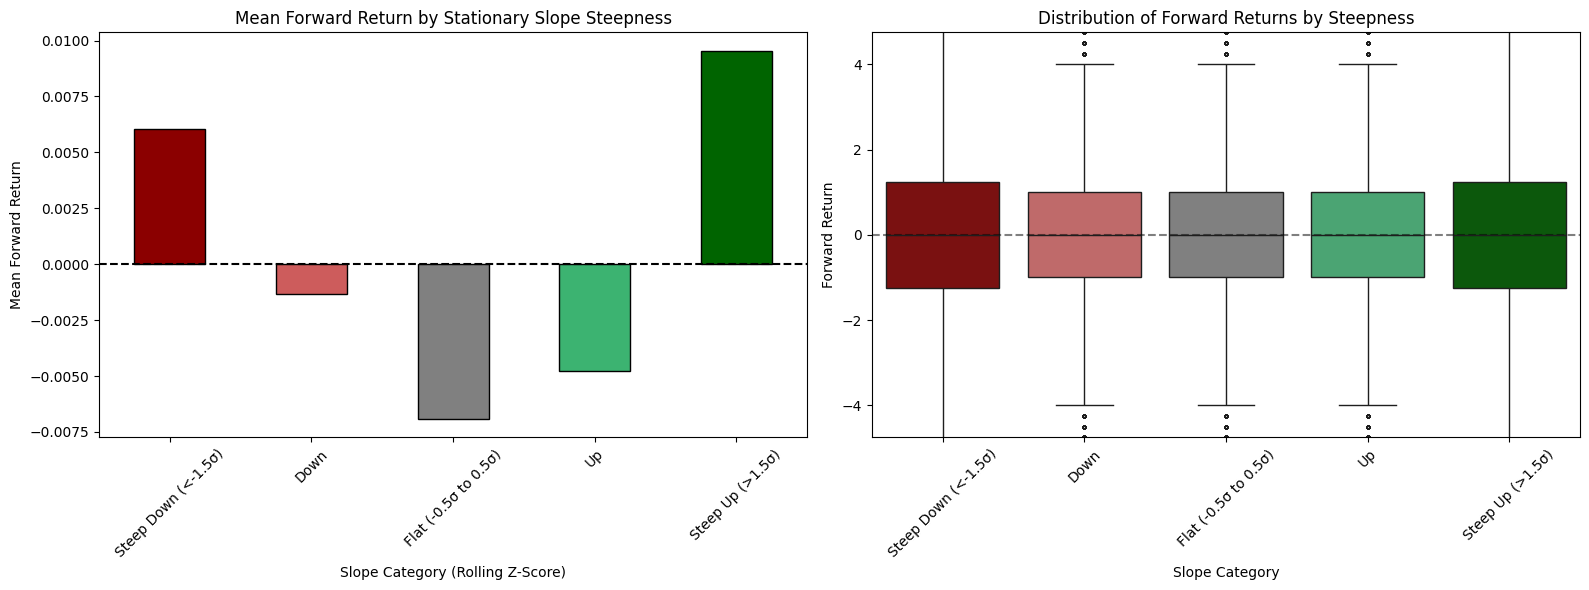

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    'close': close,
    'no_trend': no_trend
})

# 1. Forward Returns
df['fwd_returns'] = df['close'].shift(-1) - df['close']

# 2. Stationary Slope Calculation
# Raw slope is the 1-period difference
df['raw_slope'] = df['no_trend'].diff()

# Normalize to make it stationary (Rolling Z-Score)
# A 100-period window contextualizes the slope against recent market volatility
lookback_window = 100
df['slope_mean'] = df['raw_slope'].rolling(window=lookback_window).mean()
df['slope_std'] = df['raw_slope'].rolling(window=lookback_window).std()

# Z-score guarantees the metric is stationary and centered around 0
df['stat_slope'] = (df['raw_slope'] - df['slope_mean']) / df['slope_std']

# 3. Categorize Steepness
# Classify the stationary slope into discrete bins based on standard deviations
bins = [-np.inf, -1.5, -0.5, 0.5, 1.5, np.inf]
labels = ['Steep Down (<-1.5σ)', 'Down', 'Flat (-0.5σ to 0.5σ)', 'Up', 'Steep Up (>1.5σ)']
df['slope_category'] = pd.cut(df['stat_slope'], bins=bins, labels=labels)

df = df.dropna()

# 4. Statistical Analysis
stats = df.groupby('slope_category', observed=False)['fwd_returns'].agg(
    mean_return='mean',
    std_dev='std',
    count='count'
)
stats['win_rate'] = df.groupby('slope_category', observed=False)['fwd_returns'].apply(lambda x: (x > 0).mean())

print("--- Forward Returns by Stationary Slope Category ---")
print(stats.to_string())

# 5. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Mean Returns by Category
colors = ['darkred', 'indianred', 'gray', 'mediumseagreen', 'darkgreen']
stats['mean_return'].plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Mean Forward Return by Stationary Slope Steepness')
axes[0].set_ylabel('Mean Forward Return')
axes[0].set_xlabel('Slope Category (Rolling Z-Score)')
axes[0].axhline(0, color='black', linestyle='--')
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Return Distributions
sns.boxplot(
    x='slope_category', y='fwd_returns', hue='slope_category', 
    data=df, ax=axes[1], palette=colors, legend=False, fliersize=2
)
axes[1].set_title('Distribution of Forward Returns by Steepness')
axes[1].set_ylabel('Forward Return')
axes[1].set_xlabel('Slope Category')
axes[1].axhline(0, color='black', linestyle='--', alpha=0.5)
axes[1].tick_params(axis='x', rotation=45)

# Dynamically constrain y-axis to the 1st and 99th percentiles to prevent extreme outliers from crushing the boxplot scale
q_low = df['fwd_returns'].quantile(0.01)
q_high = df['fwd_returns'].quantile(0.99)
axes[1].set_ylim(q_low, q_high)

plt.tight_layout()
plt.show()

In [35]:
# Signal generation
signal = np.zeros(n_bars)
position = 0
warmup = 90

# Lookahead bias removed
# no_trend = np.roll(no_trend, shift=-1)  

for i in range(warmup, n_bars):
    # Calculate the discrete second derivative (acceleration)
    # a[i] = v[i] - v[i-1] = (x[i] - x[i-1]) - (x[i-1] - x[i-2])
    acceleration = no_trend[i] - 2 * no_trend[i-1] + no_trend[i-2]
    
    if acceleration > 0:
        position = 1   # long
    elif acceleration < 0:
        position = -1  # short
    else:
        position = 0   # flat
        
    signal[i] = position

n_trades = int(np.sum(np.abs(np.diff(signal)) > 0))
n_long = int(np.sum(signal == 1))
n_short = int(np.sum(signal == -1))
n_flat = int(np.sum(signal == 0))

print(f'Jill Flips: {np.where(np.diff(signal) != 0)[0]}')
print(f'Total trades: {n_trades:,}')
print(f'Bars long: {n_long:,} | Bars short: {n_short:,} | Bars flat: {n_flat:,}')
print(f'Time in market: {(n_long + n_short) / n_bars * 100:.1f}%')

Jill Flips: [   89    91    93 ... 66423 66428 66430]
Total trades: 12,298
Bars long: 32,715 | Bars short: 33,635 | Bars flat: 90
Time in market: 99.9%


--- Distribution Percentiles ---
1st Percentile:  -4.5278
95th Percentile: 2.9188
99th Percentile: 4.6855


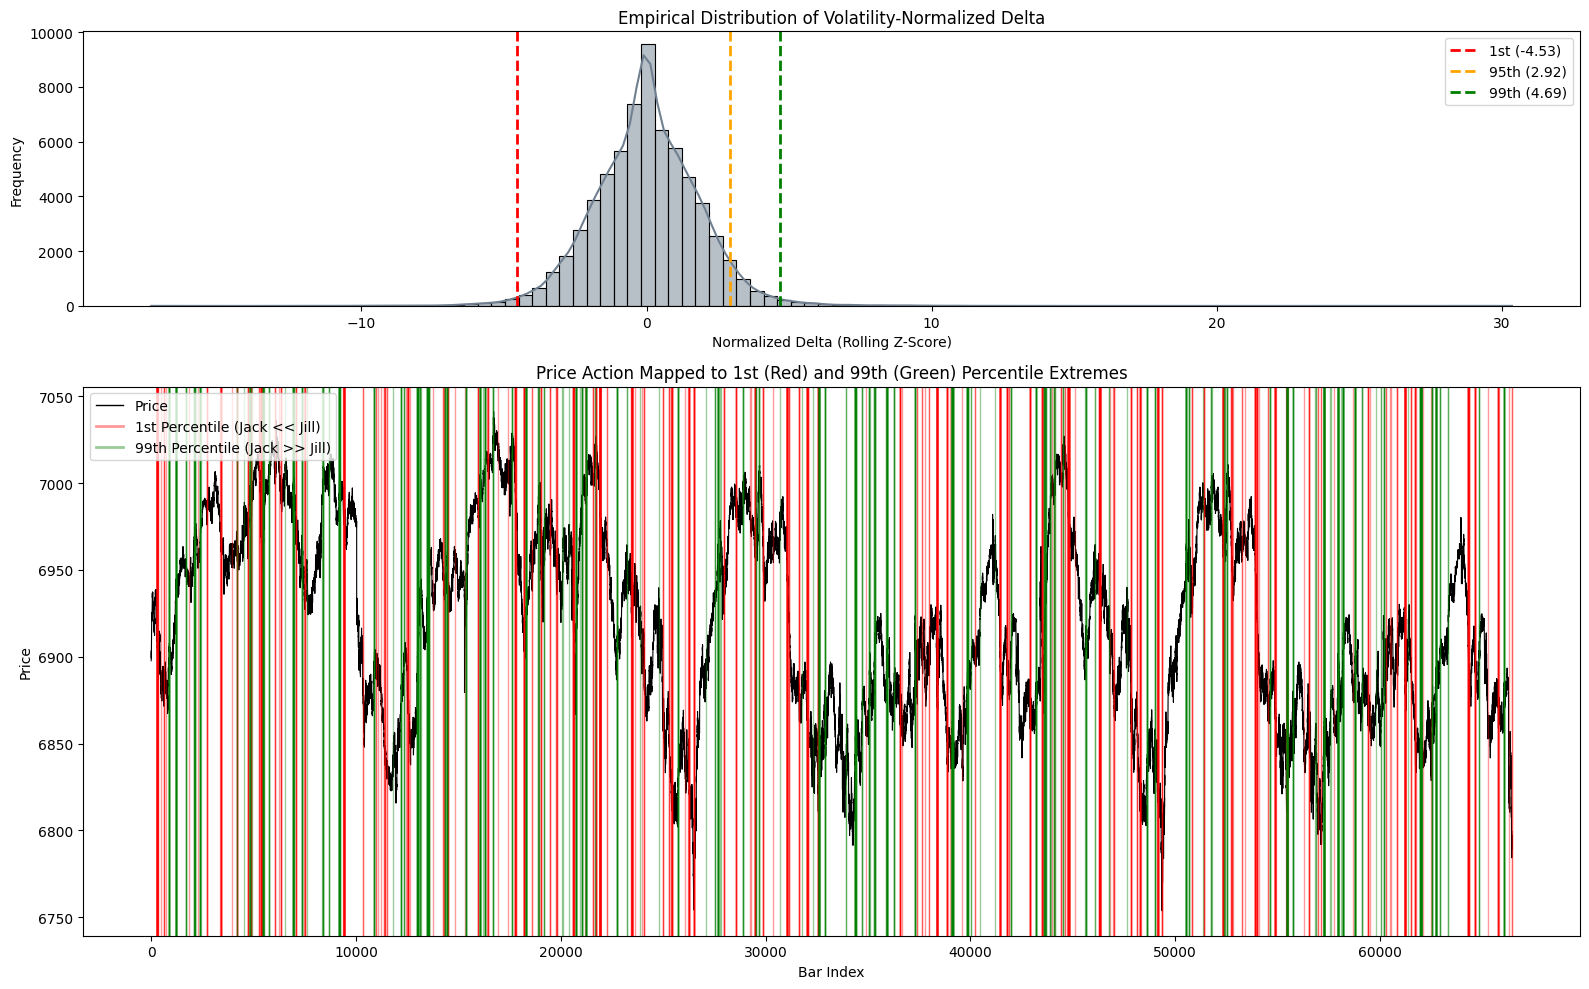

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate Jack and Jill with identical periods
jack = adaptive_supersmoother(close, default_period=20, is_contra_trend=False)
jill = adaptive_supersmoother(close, default_period=20, is_contra_trend=True)

# 2. Calculate and Normalize the Difference
delta = jack - jill
delta_series = pd.Series(delta)

# Normalize by 20-bar rolling standard deviation
rolling_std = delta_series.rolling(window=20).std()
rolling_std = rolling_std.replace(0, np.nan) # Prevent division by zero
norm_delta = delta_series / rolling_std

# Drop NaN values from warmup/rolling windows
clean_norm_delta = norm_delta.dropna()

# 3. Extract Percentiles
p_01 = np.percentile(clean_norm_delta, 1)
p_95 = np.percentile(clean_norm_delta, 95)
p_99 = np.percentile(clean_norm_delta, 99)

print("--- Distribution Percentiles ---")
print(f"1st Percentile:  {p_01:.4f}")
print(f"95th Percentile: {p_95:.4f}")
print(f"99th Percentile: {p_99:.4f}")

# 4. Map Extreme Action Points
extreme_low_idx = norm_delta[norm_delta <= p_01].index
extreme_high_idx = norm_delta[norm_delta >= p_99].index

# 5. Visualizations
fig, axes = plt.subplots(2, 1, figsize=(16, 10), gridspec_kw={'height_ratios': [1, 2]})

# Plot A: Distribution of Normalized Delta
sns.histplot(clean_norm_delta, kde=True, ax=axes[0], color='slategray', bins=100)
axes[0].axvline(p_01, color='red', linestyle='--', linewidth=2, label=f'1st ({p_01:.2f})')
axes[0].axvline(p_95, color='orange', linestyle='--', linewidth=2, label=f'95th ({p_95:.2f})')
axes[0].axvline(p_99, color='green', linestyle='--', linewidth=2, label=f'99th ({p_99:.2f})')
axes[0].set_title('Empirical Distribution of Volatility-Normalized Delta')
axes[0].set_xlabel('Normalized Delta (Rolling Z-Score)')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Plot B: Price Chart with Extreme Vertical Lines
axes[1].plot(close, color='black', linewidth=0.8, label='Price (Close)')

# Draw vertical lines for the 1st and 99th percentiles
for idx in extreme_low_idx:
    axes[1].axvline(idx, color='red', alpha=0.4, linewidth=1)
for idx in extreme_high_idx:
    axes[1].axvline(idx, color='green', alpha=0.4, linewidth=1)

axes[1].set_title('Price Action Mapped to 1st (Red) and 99th (Green) Percentile Extremes')
axes[1].set_xlabel('Bar Index')
axes[1].set_ylabel('Price')

# Custom legend handling for the vertical lines
from matplotlib.lines import Line2D
custom_lines = [
    Line2D([0], [0], color='black', lw=1),
    Line2D([0], [0], color='red', alpha=0.4, lw=2),
    Line2D([0], [0], color='green', alpha=0.4, lw=2)
]
axes[1].legend(custom_lines, ['Price', '1st Percentile (Jack << Jill)', '99th Percentile (Jack >> Jill)'], loc='upper left')

plt.tight_layout()
plt.show()

c:\Users\ryany\OneDrive\Desktop\Futures-PC\MacLink\RugbeatunoBacktestingSuite\Engine\Backtester.py:430: RuntimeWarning: invalid value encountered in scalar power
  self.CAGR = ((self.final_equity / self.initial_equity)
c:\Users\ryany\OneDrive\Desktop\Futures-PC\MacLink\RugbeatunoBacktestingSuite\Engine\Backtester.py:489: RuntimeWarning: overflow encountered in scalar power
  strat_annual = (1 + strategy_returns.mean()) ** bars_annually - 1


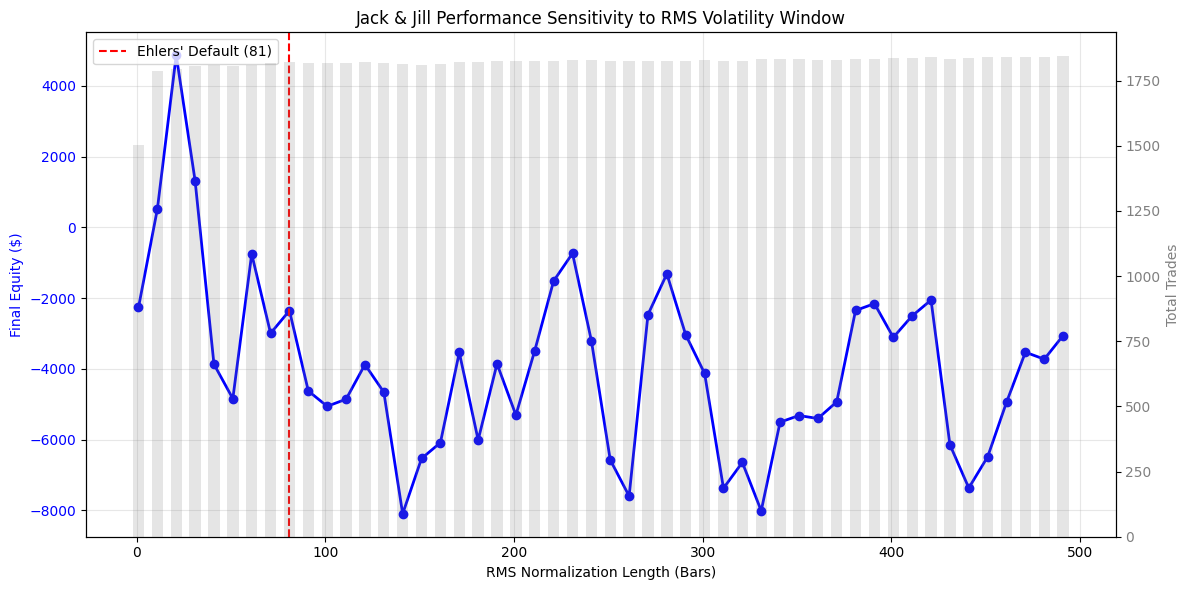

--- RMS Window Optimization Results ---
Peak Equity RMS Length: 21
Peak Final Equity: $4,865.75


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define Jack & Jill Core Logic with Variable RMS Length
def jack_jill_filter(price, default_period=20, is_contra_trend=False, rms_length=81):
    n = len(price)
    out = np.copy(price)
    period = np.full(n, default_period, dtype=float)
    
    # Calculate difference
    diff = np.zeros(n)
    diff[1:] = price[1:] - price[:-1]
    
    # Calculate rolling RMS of the difference
    diff_sq = diff ** 2
    # Use pandas rolling mean for efficient RMS computation
    rms = np.sqrt(pd.Series(diff_sq).rolling(window=rms_length, min_periods=1).mean().values)
    
    for i in range(4, n):
        # Normalize ROC
        roc = 0
        if rms[i] != 0:
            roc = abs(diff[i] / rms[i])
        
        # Hard cap at 2 standard deviations (per Ehlers' spec)
        roc = min(roc, 2.0)
        
        # Determine Period scaling based on Jack vs Jill
        if is_contra_trend:
            # Jill: expands period with volatility
            next_period = default_period * (1 + 0.5 * roc)**2
        else:
            # Jack: contracts period with volatility
            next_period = default_period * (1 - 0.5 * roc)**2
            next_period = max(next_period, 2.0)
            
        period[i] = next_period
        
        # SuperSmoother coefficients based on dynamic period
        curr_p = period[i-1] # Use previous bar's calculated period for current smoothing
        Q = np.exp(-1.414 * np.pi / curr_p)
        c1 = 2 * Q * np.cos(1.414 * np.pi / curr_p)
        c2 = Q * Q
        a0 = (1 - c1 + c2) / 2
        
        out[i] = a0 * (price[i] + price[i-1]) + c1 * out[i-1] - c2 * out[i-2]
        
    return out

# 2. Setup Sweep Parameters
rms_lengths = range(1, 500, 10)
default_p = 20
warmup = 150
n_bars = len(close)

results = []

# 3. Execute Grid Search
for rms_len in rms_lengths:
    
    # Compute Jack (Fast) and Jill (Slow)
    jack = jack_jill_filter(close, default_period=default_p, is_contra_trend=False, rms_length=rms_len)
    jill = jack_jill_filter(close, default_period=default_p, is_contra_trend=True, rms_length=rms_len)

    
    # Generate continuous reversal signals (Jack > Jill = Long, Jack < Jill = Short)
    # signal = np.zeros(n_bars)
    jill_diff = np.diff(jill, prepend=jill[0])
    signal = -np.sign(jill_diff)
    
    # Execute Backtest
    bt = Backtester(
        ohlc=ohlc,
        indicies=indices,
        signal=signal,
        timeframe=timeframe,
        tick_value=tick_value,
        contract_multiplier=contract_multiplier,
        initial_equity=initial_equity,
        slippage_ticks=1.0,
        commission=3.50,
    )
    bt.full_backtest()
    
    results.append({
        'RMS_Length': rms_len,
        'Final_Equity': bt.final_equity,
        'Total_Trades': int(np.sum(np.abs(np.diff(signal[warmup:])) > 0)) / 2
    })

# 4. Analyze and Visualize Results
df_results = pd.DataFrame(results)

fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Equity
ax1.plot(df_results['RMS_Length'], df_results['Final_Equity'], color='blue', marker='o', linewidth=2)
ax1.set_xlabel('RMS Normalization Length (Bars)')
ax1.set_ylabel('Final Equity ($)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.grid(True, alpha=0.3)
ax1.axvline(81, color='red', linestyle='--', label="Ehlers' Default (81)")
ax1.legend(loc='upper left')

# Plot Trade Frequency
ax2 = ax1.twinx()
ax2.bar(df_results['RMS_Length'], df_results['Total_Trades'], alpha=0.2, color='gray', width=6)
ax2.set_ylabel('Total Trades', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

plt.title('Jack & Jill Performance Sensitivity to RMS Volatility Window')
fig.tight_layout()
plt.show()

print("--- RMS Window Optimization Results ---")
optimal_row = df_results.loc[df_results['Final_Equity'].idxmax()]
print(f"Peak Equity RMS Length: {optimal_row['RMS_Length']:.0f}")
print(f"Peak Final Equity: ${optimal_row['Final_Equity']:,.2f}")

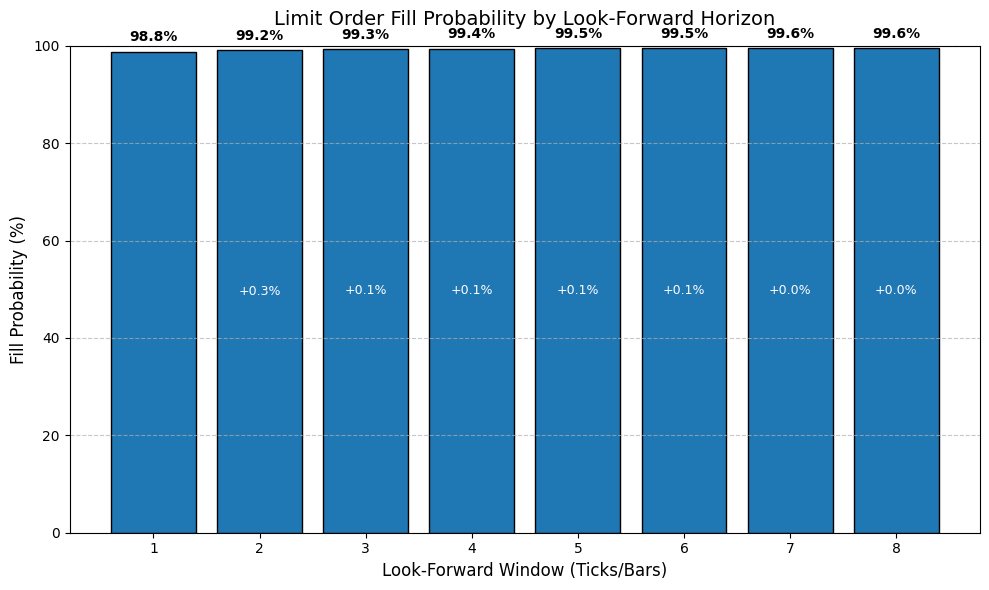

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Core parameters
tick_size = 0.25
max_look_forward = 8
look_forwards = np.arange(1, max_look_forward + 1)
fill_rates = []

# Extract arrays
O, H, L, C = ohlc[:, 0], ohlc[:, 1], ohlc[:, 2], ohlc[:, 3]

# 1. Generate a static array of random signals for a controlled experiment
# 1 = Long, -1 = Short, 0 = No action
np.random.seed(42)
rand_vals = np.random.rand(n_bars)
signals = np.zeros(n_bars, dtype=int)
signals[rand_vals < 0.10] = 1
signals[(rand_vals >= 0.10) & (rand_vals < 0.20)] = -1

# 2. Iteratively test the exact same signals against expanding time horizons
for lf in look_forwards:
    fills = 0
    valid_signals = 0
    
    for i in range(n_bars - max_look_forward):
        direction = signals[i]
        if direction == 0:
            continue
            
        valid_signals += 1
        limit_price = O[i]
        
        # Evaluate localized horizon
        # Evaluate localized horizon
        for j in range(i, i + lf):
            if direction == 1:
                # Strictly traded through
                if L[j] <= limit_price - tick_size:
                    fills += 1
                    break
            elif direction == -1:
                # Strictly traded through
                if H[j] >= limit_price + tick_size:
                    fills += 1
                    break
                    
    rate = fills / valid_signals if valid_signals > 0 else 0
    fill_rates.append(rate)

# 3. Visualize the asymptotic fill distribution
plt.figure(figsize=(10, 6))
bars = plt.bar(look_forwards, [r * 100 for r in fill_rates], color='#1f77b4', edgecolor='black')

# Formatting for analytical clarity
plt.title('Limit Order Fill Probability by Look-Forward Horizon', fontsize=14, pad=15)
plt.xlabel('Look-Forward Window (Ticks/Bars)', fontsize=12)
plt.ylabel('Fill Probability (%)', fontsize=12)
plt.ylim(0, 100)
plt.xticks(look_forwards)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Annotate marginal gains
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1.5,
             f'{height:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    if i > 0:
        marginal_gain = height - bars[i-1].get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height/2,
                 f'+{marginal_gain:.1f}%', ha='center', va='center', color='white', fontsize=9)

plt.tight_layout()
plt.show()

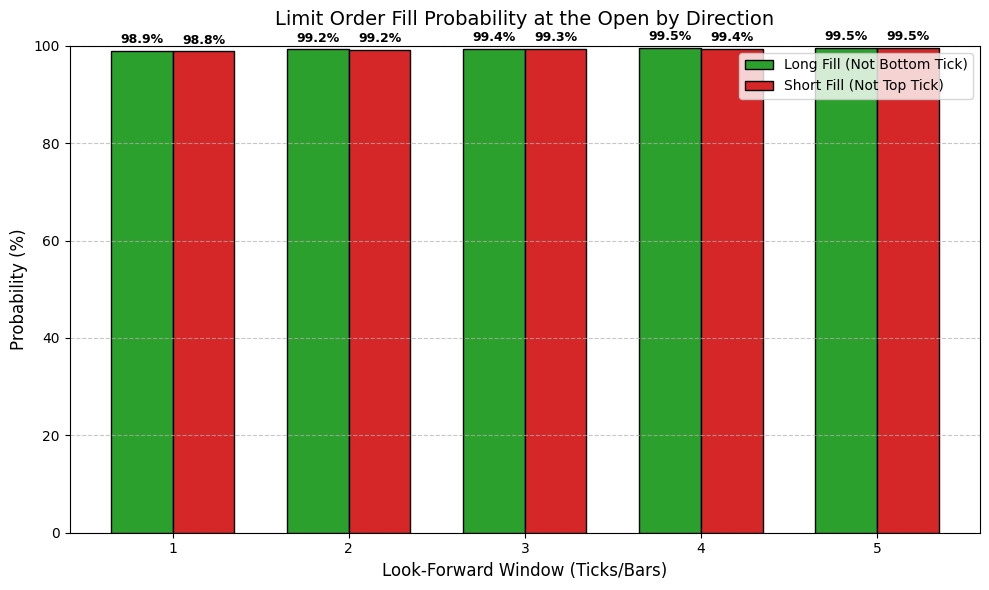

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Core parameters
max_look_forward = 5
look_forwards = np.arange(1, max_look_forward + 1)

long_fill_rates = []
short_fill_rates = []

n_bars = len(O)

for lf in look_forwards:
    # 1. Generate rolling windows for the look-forward horizon
    valid_len = n_bars - lf + 1
    
    # Calculate absolute min and max of the future window for every bar
    min_L = np.array([np.min(L[i:i+lf]) for i in range(valid_len)])
    max_H = np.array([np.max(H[i:i+lf]) for i in range(valid_len)])
    O_curr = O[:valid_len]
    
    # 2. Long Fill: Price trades at least one tick below the open
    # (The open was NOT the absolute bottom tick)
    filled_long = min_L <= (O_curr - tick_size)
    
    # 3. Short Fill: Price trades at least one tick above the open
    # (The open was NOT the absolute top tick)
    filled_short = max_H >= (O_curr + tick_size)
    
    long_fill_rates.append(np.mean(filled_long))
    short_fill_rates.append(np.mean(filled_short))

# 4. Visualize the probability distribution (Grouped Bar Chart)
fig, ax = plt.subplots(figsize=(10, 6))

bar_width = 0.35
x = np.arange(len(look_forwards))

bars_long = ax.bar(x - bar_width/2, [r * 100 for r in long_fill_rates], 
                   bar_width, label='Long Fill (Not Bottom Tick)', color='#2ca02c', edgecolor='black')
bars_short = ax.bar(x + bar_width/2, [r * 100 for r in short_fill_rates], 
                    bar_width, label='Short Fill (Not Top Tick)', color='#d62728', edgecolor='black')

ax.set_title('Limit Order Fill Probability at the Open by Direction', fontsize=14, pad=15)
ax.set_xlabel('Look-Forward Window (Ticks/Bars)', fontsize=12)
ax.set_ylabel('Probability (%)', fontsize=12)
ax.set_ylim(0, 100)
ax.set_xticks(x)
ax.set_xticklabels(look_forwards)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Annotate bars
for bars in [bars_long, bars_short]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 1,
                f'{height:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

In [18]:
import numpy as np

max_lf = 50
valid_len = len(O) - max_lf
O_curr = O[:valid_len]

print("--- LONG LIMIT ORDERS ---")
not_filled_yet_long = np.ones(valid_len, dtype=bool)

for n in range(1, max_lf + 1):
    L_nth_bar = L[n-1 : valid_len + n - 1]
    filled_this_bar_long = L_nth_bar <= (O_curr - tick_size)
    
    if n == 1:
        rate = np.mean(filled_this_bar_long)
        print(f"Bar {n} Unconditional P(Fill): {rate * 100:.2f}%")
    else:
        valid_denominators = np.sum(not_filled_yet_long)
        if valid_denominators > 0:
            cond_rate = np.sum(not_filled_yet_long & filled_this_bar_long) / valid_denominators
            print(f"Bar {n} Conditional P(Fill | Not Filled 1 to {n-1}): {cond_rate * 100:.2f}%")
            
    not_filled_yet_long = not_filled_yet_long & ~filled_this_bar_long

print("\n--- SHORT LIMIT ORDERS ---")
not_filled_yet_short = np.ones(valid_len, dtype=bool)

for n in range(1, max_lf + 1):
    H_nth_bar = H[n-1 : valid_len + n - 1]
    filled_this_bar_short = H_nth_bar >= (O_curr + tick_size)
    
    if n == 1:
        rate = np.mean(filled_this_bar_short)
        print(f"Bar {n} Unconditional P(Fill): {rate * 100:.2f}%")
    else:
        valid_denominators = np.sum(not_filled_yet_short)
        if valid_denominators > 0:
            cond_rate = np.sum(not_filled_yet_short & filled_this_bar_short) / valid_denominators
            print(f"Bar {n} Conditional P(Fill | Not Filled 1 to {n-1}): {cond_rate * 100:.2f}%")
            
    not_filled_yet_short = not_filled_yet_short & ~filled_this_bar_short

--- LONG LIMIT ORDERS ---
Bar 1 Unconditional P(Fill): 98.93%
Bar 2 Conditional P(Fill | Not Filled 1 to 1): 29.72%
Bar 3 Conditional P(Fill | Not Filled 1 to 2): 19.44%
Bar 4 Conditional P(Fill | Not Filled 1 to 3): 15.17%
Bar 5 Conditional P(Fill | Not Filled 1 to 4): 11.44%
Bar 6 Conditional P(Fill | Not Filled 1 to 5): 7.95%
Bar 7 Conditional P(Fill | Not Filled 1 to 6): 7.19%
Bar 8 Conditional P(Fill | Not Filled 1 to 7): 7.36%
Bar 9 Conditional P(Fill | Not Filled 1 to 8): 2.93%
Bar 10 Conditional P(Fill | Not Filled 1 to 9): 4.74%
Bar 11 Conditional P(Fill | Not Filled 1 to 10): 7.24%
Bar 12 Conditional P(Fill | Not Filled 1 to 11): 2.44%
Bar 13 Conditional P(Fill | Not Filled 1 to 12): 4.00%
Bar 14 Conditional P(Fill | Not Filled 1 to 13): 3.65%
Bar 15 Conditional P(Fill | Not Filled 1 to 14): 2.16%
Bar 16 Conditional P(Fill | Not Filled 1 to 15): 2.76%
Bar 17 Conditional P(Fill | Not Filled 1 to 16): 3.41%
Bar 18 Conditional P(Fill | Not Filled 1 to 17): 4.12%
Bar 19 Condition

In [ ]:
jack = jack_jill_filter(close, default_period=default_p, is_contra_trend=False, rms_length=81)
jill = jack_jill_filter(close, default_period=default_p, is_contra_trend=True, rms_length=20)
jill = np.roll(jill, shift=-4)

# Generate continuous reversal signals (Jack > Jill = Long, Jack < Jill = Short)
# signal = np.zeros(n_bars)
jill_diff = np.diff(jill, prepend=jill[0])
signal = np.sign(jill_diff)


bt = Backtester(
    ohlc=ohlc,
    indicies=indices,
    signal=signal,
    timeframe=timeframe,
    tick_value=tick_value,
    contract_multiplier=contract_multiplier,
    initial_equity=initial_equity,
    slippage_ticks=1.0,
    commission=3.50,
)
bt.full_backtest()
bt.final_equity
print(bt)


        Backtest Results from 2026-01-01 23:02:37.009120-06:00 to 2026-03-02 07:29:21.001600-06:00 (59 days 08:26:43.992480)
        Equity:     $100,000.00 -> $1,226,987.25
        Buy & Hold: $100,000.00 -> $94,850.00
        Buy & Hold Return (%): -5.15%
        Strategy Return (%):   1126.99%

        Total Trades:     3597.00
        Win Rate:         84.77%
        95% CI:           83.55% - 85.90%
        Avg. Win:         $381.84
        Avg. Loss:        $-67.94
        Ratio Win/Loss:   5.62
        Expected Value:   $313.31

        Largest Win:      $3,634.00
        Largest Loss:     $-391.00
        Max Consec. Wins: 38
        Max Consec. Loss: 4

        Max Drawdown from 2026-02-25 22:30:12.005680-06:00 to 2026-02-25 23:29:12.000280-06:00 (0 days 00:58:59.994600)
        Max Drawdown:     $-1,669.50
        Max Drawdown (%): -0.22%

        Slippage:   1.0 ticks
        Commission: $3.50
        Contract Multiplier: $50.00
        Transaction Costs:   $102,500.25

   

In [26]:
from Engine.Report import generate_report
generate_report(bt, 'backtest_report.html', open_browser=True)

Report saved: C:\Users\ryany\OneDrive\Desktop\Futures-PC\MacLink\RugbeatunoBacktestingSuite\backtest_report.html


'C:\\Users\\ryany\\OneDrive\\Desktop\\Futures-PC\\MacLink\\RugbeatunoBacktestingSuite\\backtest_report.html'